# Segmentation des patients diabétiques hospitalisés — Clustering (k = 2)
### Dataset : *Diabetes 130-US hospitals (1999–2008)*

---

## Objectif du TP
Regrouper les patients diabétiques hospitalisés en **2 groupes (clusters)** de profils cliniques similaires, **sans utiliser la variable cible** `readmitted`, puis :
1. comparer **plusieurs algorithmes de clustering** (KMeans, GMM, hiérarchique, DBSCAN, K-Prototypes, Gower + K-Medoids) avec **k = 2** ;
2. **interpréter** les 2 groupes obtenus (qui sont ces patients ?) ;
3. **évaluer** la qualité du clustering (métriques internes, stabilité, validation externe par la réadmission) ;
4. **mesurer ce que l'on gagne et ce que l'on perd** en choisissant k = 2 plutôt que k = 3.

## Plan du notebook

| Partie | Contenu |
|---|---|
| **0** | Configuration et imports |
| **1** | Chargement et exploration des données brutes |
| **2** | Nettoyage (lignes et colonnes) |
| **3** | Création / regroupement des variables (feature engineering) |
| **4** | Encodage et mise à l'échelle |
| **5** | Réduction de dimension (PCA) |
| **6** | Justification du choix k = 2 |
| **7** | Clustering final KMeans k = 2 + visualisation + profil des clusters + modèle de substitution + comparaison k = 2 / k = 3 |
| **8** | Comparaison des algorithmes de clustering (k = 2) |
| **9** | Méthodes pour variables mixtes (K-Prototypes, Gower + K-Medoids) et notation /10 |
| **10** | Validation externe : lien avec la réadmission (χ², V de Cramér, odds ratio) |
| **11** | Interprétation des 2 clusters |
| **12** | Évaluation globale et conclusion |
| **13** | Sauvegarde des résultats |
| **14** | Export du bundle pour déploiement web (DiaCareApp) |

> **Fichiers nécessaires** dans le même dossier que ce notebook : `diabetic_data.csv`.

## 0. Configuration et imports

On fixe ici les paramètres globaux :
- `K = 2` : nombre de clusters imposé pour tout le TP ;
- `N_SAMPLE` : taille de l'échantillon utilisé pour les algorithmes coûteux (hiérarchique, DBSCAN, GMM). Ils ont une complexité en O(n²) et ne passent pas sur ~70 000 lignes ; **tous les algorithmes sont comparés sur les mêmes points** pour que la comparaison soit équitable ;
- `RANDOM_STATE` : graine aléatoire pour que les résultats soient reproductibles.

In [1]:
import time, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 100

RANDOM_STATE = 42
K = 2                      # nombre de clusters imposé
N_SAMPLE = 10000           # taille de l'échantillon pour la comparaison (baisser si manque de RAM)
DATA_PATH = "diabetic_data.csv"

## 1. Chargement et exploration des données brutes

Le fichier contient un enregistrement par **séjour hospitalier** de patients diabétiques (130 hôpitaux américains).

Dans ce fichier, les valeurs manquantes sont codées `?`, `NULL`, `Not Available`, `Not Mapped` ou `Unknown/Invalid`. On les convertit en `NaN` dès la lecture.

> ⚠️ **Point d'attention :** pandas considère aussi le texte `None` comme manquant. Pour `A1Cresult` et `max_glu_serum`, `None` signifie en réalité « analyse **non réalisée** » : ce n'est pas une vraie valeur manquante, on le traitera à l'étape 2.

In [2]:
df = pd.read_csv(DATA_PATH, na_values=["?", "NULL", "Not Available", "Not Mapped", "Unknown/Invalid"])
print("Dimensions brutes :", df.shape)
df.head(3)

Dimensions brutes : (101766, 50)


,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,...,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),NaN,6,25,1,1,...,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),NaN,1,1,7,3,...,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),NaN,1,1,7,2,...,No,No,No,No,No,No,No,No,Yes,NO


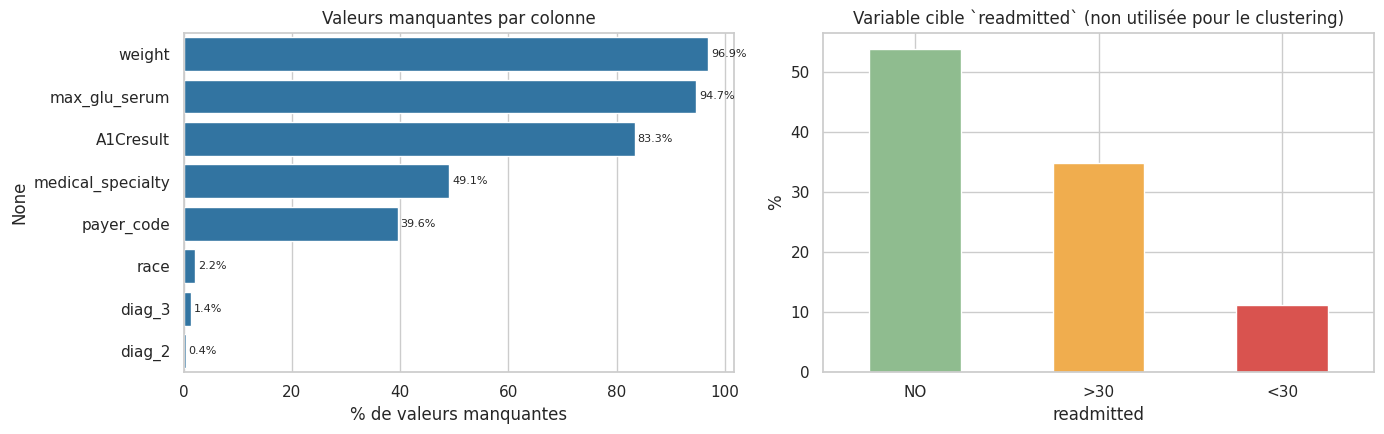

In [3]:
# Pourcentage de valeurs manquantes par colonne
miss = df.isna().mean().mul(100).round(1).sort_values(ascending=False)
miss = miss[miss > 0]

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
sns.barplot(x=miss.values, y=miss.index, ax=ax[0], color="tab:blue")
ax[0].set_xlabel("% de valeurs manquantes"); ax[0].set_title("Valeurs manquantes par colonne")
for i, v in enumerate(miss.values): ax[0].text(v + 0.5, i, f"{v}%", va="center", fontsize=8)

df["readmitted"].value_counts(normalize=True).mul(100).round(1).reindex(["NO", ">30", "<30"]).plot(
    kind="bar", ax=ax[1], color=["#8fbc8f", "#f0ad4e", "#d9534f"])
ax[1].set_title("Variable cible `readmitted` (non utilisée pour le clustering)"); ax[1].set_ylabel("%"); ax[1].tick_params(axis="x", rotation=0)
plt.tight_layout(); plt.show()

**Lecture :**
- `weight` (≈97 %), `max_glu_serum` et `A1Cresult` (NaN = « non testé »), `medical_specialty` (≈49 %) et `payer_code` (≈40 %) sont très incomplètes.
- La cible `readmitted` a trois modalités : `NO` (pas de réadmission), `>30` (réadmission après 30 jours), `<30` (réadmission sous 30 jours). Elle **n'entre pas** dans le clustering : on l'utilisera uniquement à la fin pour **valider** les groupes (validation externe).

## 2. Nettoyage

### 2.1 Lignes supprimées
| Règle | Justification |
|---|---|
| Patients décédés ou en hospice (`discharge_disposition_id` ∈ {11, 13, 14, 19, 20, 21}) | Ils ne peuvent pas être réadmis : ils fausseraient l'interprétation |
| `gender` invalide ou `diag_1` manquant | Information essentielle absente (très peu de lignes) |
| Doublons patients : **1 séjour par patient** (le premier) | Un même patient présent plusieurs fois donnerait des lignes non indépendantes |

### 2.2 Colonnes supprimées
| Colonne(s) | Justification |
|---|---|
| `encounter_id`, `patient_nbr` | Simples identifiants |
| `weight` (97 % NaN), `payer_code` (40 %), `medical_specialty` (49 %) | Trop incomplètes |
| `race` | Peu de NaN mais peu pertinente pour un profil clinique |
| `diag_2`, `diag_3` | ~750 modalités chacune : on garde seulement `diag_1` regroupé |
| 15 médicaments quasi constants (> 99 % « No ») | Aucune information discriminante |
| `readmitted` | Retirée des variables, gardée à part pour la validation |

### 2.3 Valeurs manquantes conservées comme information
`A1Cresult` et `max_glu_serum` : NaN = analyse non réalisée → catégorie **`NotTested`** (c'est un comportement médical informatif).

In [4]:
log = [("Données brutes", len(df))]

# (a) retrait des décès / hospices
dead_hospice = [11, 13, 14, 19, 20, 21]
d = df[~df["discharge_disposition_id"].isin(dead_hospice)].copy()
log.append(("Sans décès / hospice", len(d)))

# (b) sexe et diagnostic principal obligatoires
d = d.dropna(subset=["gender", "diag_1"])
log.append(("Sans gender / diag_1 manquants", len(d)))

# (c) un seul séjour par patient (le plus ancien)
d = d.sort_values("encounter_id").drop_duplicates("patient_nbr", keep="first")
log.append(("1 séjour par patient", len(d)))

# (d) NaN = analyse non faite
d["A1Cresult"] = d["A1Cresult"].fillna("NotTested")
d["max_glu_serum"] = d["max_glu_serum"].fillna("NotTested")

# (e) cible gardée à part (profilage et validation uniquement)
target = d["readmitted"].copy()

steps = pd.DataFrame(log, columns=["étape", "lignes restantes"])
steps["lignes supprimées"] = (-steps["lignes restantes"].diff()).fillna(0).astype(int)
steps

,étape,lignes restantes,lignes supprimées
0,Données brutes,101766,0
1,Sans décès / hospice,99343,2423
2,Sans gender / diag_1 manquants,99320,23
3,1 séjour par patient,69979,29341


## 3. Création et regroupement des variables (feature engineering)

Pour réduire la dimension et faciliter l'interprétation :

- **`diag_group`** : le code diagnostic ICD-9 (`diag_1`) est regroupé en grandes familles (Diabète, Circulatoire, Respiratoire, Digestif, etc.).
- **`admission_type`, `admission_source`, `discharge`** : les identifiants numériques sont regroupés en quelques catégories lisibles.
- **`age_num`** : la tranche d'âge (`[60-70)`) est convertie en nombre (milieu de la tranche : 65).
- **Médicaments** : au lieu de garder 23 colonnes, on résume par
  - `n_meds_used` : nombre de médicaments diabétiques utilisés,
  - `n_meds_changed` : nombre de médicaments dont la dose a été modifiée (`Up`/`Down`),
  - indicateurs binaires pour l'insuline et la metformine (les deux plus fréquents).

In [5]:
def icd9_group(code):
    c = str(code)
    if c.startswith(("V", "E")): return "Other"
    x = float(c)
    if 250 <= x < 251: return "Diabetes"
    if 390 <= x <= 459 or x == 785: return "Circulatory"
    if 460 <= x <= 519 or x == 786: return "Respiratory"
    if 520 <= x <= 579 or x == 787: return "Digestive"
    if 580 <= x <= 629 or x == 788: return "Genitourinary"
    if 800 <= x <= 999: return "Injury"
    if 710 <= x <= 739: return "Musculoskeletal"
    if 140 <= x <= 239: return "Neoplasms"
    return "Other"

def adm_type(x):  return {1: "Emergency", 2: "Urgent", 3: "Elective"}.get(x, "OtherType")
def adm_src(x):
    if x == 7: return "ER"
    if x in (1, 2, 3): return "Referral"
    if x in (4, 5, 6, 10, 18, 19, 22, 25, 26): return "Transfer"
    return "OtherSource"
def dis(x):
    if x in (1, 6, 8): return "Home"
    if x in (3, 4, 5, 22, 23, 24, 27, 28, 29, 30, 2, 15, 16, 17): return "Facility"
    return "OtherDischarge"

d["diag_group"]       = d["diag_1"].apply(icd9_group)
d["admission_type"]   = d["admission_type_id"].apply(adm_type)
d["admission_source"] = d["admission_source_id"].apply(adm_src)
d["discharge"]        = d["discharge_disposition_id"].apply(dis)
d["age_num"]          = d["age"].map({f"[{i}-{i+10})": i + 5 for i in range(0, 100, 10)})

med_cols = ["metformin","repaglinide","nateglinide","chlorpropamide","glimepiride","acetohexamide",
            "glipizide","glyburide","tolbutamide","pioglitazone","rosiglitazone","acarbose","miglitol",
            "troglitazone","tolazamide","examide","citoglipton","insulin","glyburide-metformin",
            "glipizide-metformin","glimepiride-pioglitazone","metformin-rosiglitazone","metformin-pioglitazone"]
d["n_meds_used"]     = (d[med_cols] != "No").sum(axis=1)
d["n_meds_changed"]  = d[med_cols].isin(["Up", "Down"]).sum(axis=1)
d["insulin_used"]    = (d["insulin"] != "No").astype(int)
d["metformin_used"]  = (d["metformin"] != "No").astype(int)
d["change_bin"]      = (d["change"] == "Ch").astype(int)
d["diabetesMed_bin"] = (d["diabetesMed"] == "Yes").astype(int)
d["gender_male"]     = (d["gender"] == "Male").astype(int)

In [6]:
# Jeu de variables final
num_feats = ["time_in_hospital","num_lab_procedures","num_procedures","num_medications",
             "number_outpatient","number_emergency","number_inpatient","number_diagnoses",
             "age_num","n_meds_used","n_meds_changed"]
bin_feats = ["insulin_used","metformin_used","change_bin","diabetesMed_bin","gender_male"]
cat_feats = ["diag_group","admission_type","admission_source","discharge","A1Cresult","max_glu_serum"]

clean = d[num_feats + bin_feats + cat_feats].copy()
clean["readmitted"] = target            # gardée à part, hors des features
print("Dataset nettoyé :", clean.shape, "| NaN restants dans les features :", int(clean[num_feats + bin_feats + cat_feats].isna().sum().sum()))
print(f"{len(num_feats)} numériques + {len(bin_feats)} binaires + {len(cat_feats)} catégorielles")
display(clean[num_feats].describe().T.round(2))

Dataset nettoyé : (69979, 23) | NaN restants dans les features : 0
11 numériques + 5 binaires + 6 catégorielles


,count,mean,std,min,25%,50%,75%,max
time_in_hospital,69979.0,4.27,2.93,1.0,2.0,3.0,6.0,14.0
num_lab_procedures,69979.0,42.88,19.89,1.0,31.0,44.0,57.0,132.0
num_procedures,69979.0,1.43,1.76,0.0,0.0,1.0,2.0,6.0
num_medications,69979.0,15.67,8.29,1.0,10.0,14.0,20.0,81.0
number_outpatient,69979.0,0.28,1.06,0.0,0.0,0.0,0.0,42.0
number_emergency,69979.0,0.10,0.51,0.0,0.0,0.0,0.0,42.0
number_inpatient,69979.0,0.18,0.60,0.0,0.0,0.0,0.0,12.0
number_diagnoses,69979.0,7.22,2.00,1.0,6.0,8.0,9.0,16.0
age_num,69979.0,65.44,15.97,5.0,55.0,65.0,75.0,95.0
n_meds_used,69979.0,1.19,0.94,0.0,1.0,1.0,2.0,6.0


## 4. Encodage et mise à l'échelle

Les algorithmes de clustering utilisent des **distances** : toutes les variables doivent être numériques et de même ordre de grandeur.

1. **Transformation `log(1+x)`** sur les 4 variables très asymétriques (`number_outpatient`, `number_emergency`, `number_inpatient`, `num_procedures`) : la majorité des patients ont 0 et quelques-uns ont des valeurs extrêmes qui écraseraient les autres.
2. **Standardisation** (`StandardScaler`) des variables numériques : moyenne 0, écart-type 1.
3. **One-hot encoding** des variables catégorielles (une colonne 0/1 par modalité).
4. Les variables binaires restent telles quelles.

Matrice finale : (69979, 44)  ( 11 num + 5 bin + 28 one-hot )


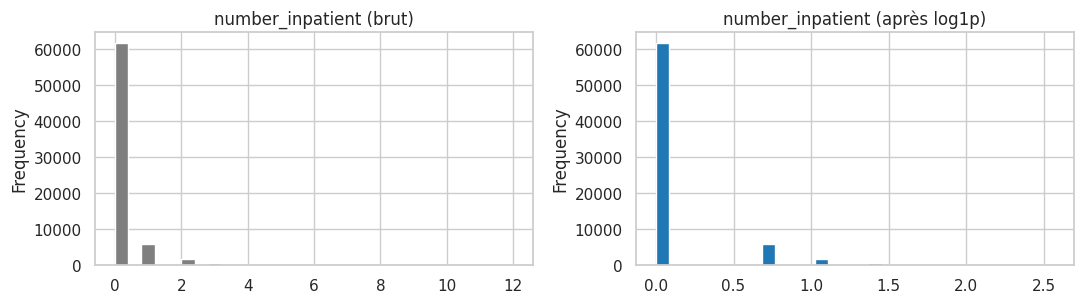

In [7]:
from sklearn.preprocessing import StandardScaler

skewed = ["number_outpatient", "number_emergency", "number_inpatient", "num_procedures"]
X_num = clean[num_feats].copy()
X_num[skewed] = np.log1p(X_num[skewed])
X_num = pd.DataFrame(StandardScaler().fit_transform(X_num), columns=num_feats, index=clean.index)
X_cat = pd.get_dummies(clean[cat_feats], dtype=int)
X = pd.concat([X_num, clean[bin_feats], X_cat], axis=1)
print("Matrice finale :", X.shape, " (", len(num_feats), "num +", len(bin_feats), "bin +", X_cat.shape[1], "one-hot )")

# Effet du log sur une variable asymétrique
fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
clean["number_inpatient"].plot(kind="hist", bins=30, ax=ax[0], color="tab:gray"); ax[0].set_title("number_inpatient (brut)")
np.log1p(clean["number_inpatient"]).plot(kind="hist", bins=30, ax=ax[1], color="tab:blue"); ax[1].set_title("number_inpatient (après log1p)")
plt.tight_layout(); plt.show()

## 5. Réduction de dimension (PCA)

Avec 44 colonnes (dont beaucoup de colonnes one-hot corrélées), les distances deviennent moins discriminantes (*malédiction de la dimension*). L'**ACP** projette les données sur des axes indépendants qui résument la variance. On garde le nombre de composantes qui conserve **90 % de la variance**.

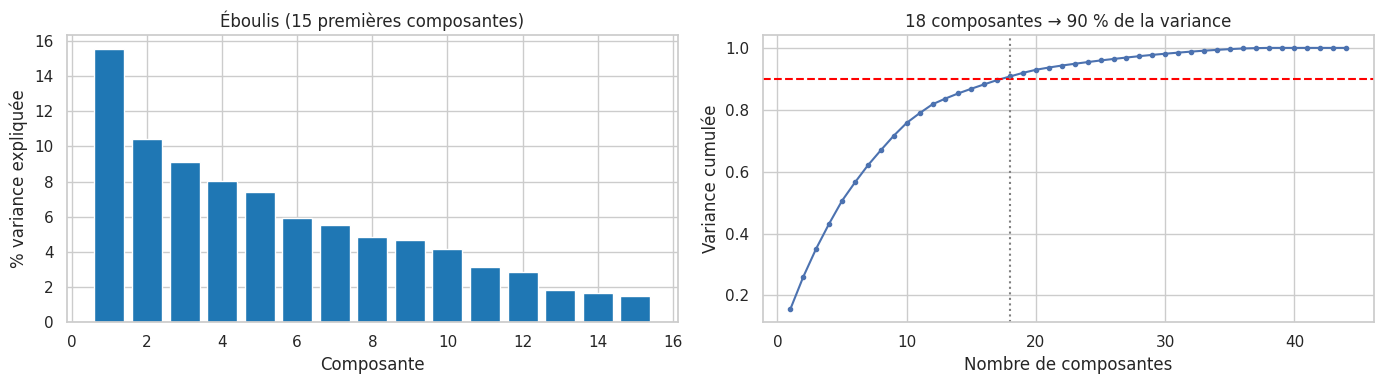

X_pca : (69979, 18)

Variables dominantes de PC1 (15.6 % de variance) :
num_medications       0.51
time_in_hospital      0.44
n_meds_changed        0.34
n_meds_used           0.32
num_lab_procedures    0.31
number_diagnoses      0.29

Variables dominantes de PC2 (10.4 % de variance) :
n_meds_used         0.53
n_meds_changed      0.41
age_num            -0.34
number_diagnoses   -0.33
change_bin          0.26
time_in_hospital   -0.24


In [8]:
from sklearn.decomposition import PCA

pca_full = PCA(random_state=RANDOM_STATE).fit(X)
cum = np.cumsum(pca_full.explained_variance_ratio_)
n_comp = int(np.argmax(cum >= 0.90)) + 1

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ax[0].bar(range(1, 16), pca_full.explained_variance_ratio_[:15] * 100, color="tab:blue")
ax[0].set_xlabel("Composante"); ax[0].set_ylabel("% variance expliquée"); ax[0].set_title("Éboulis (15 premières composantes)")
ax[1].plot(range(1, len(cum) + 1), cum, marker="o", ms=3)
ax[1].axhline(0.90, color="red", ls="--"); ax[1].axvline(n_comp, color="gray", ls=":")
ax[1].set_xlabel("Nombre de composantes"); ax[1].set_ylabel("Variance cumulée"); ax[1].set_title(f"{n_comp} composantes → 90 % de la variance")
plt.tight_layout(); plt.show()

pca = PCA(n_components=n_comp, random_state=RANDOM_STATE).fit(X)
X_pca = pca.transform(X)
print("X_pca :", X_pca.shape)

# Que représentent les 2 premiers axes ? (variables ayant les plus forts poids)
load = pd.DataFrame(pca.components_[:2].T, index=X.columns, columns=["PC1", "PC2"])
for pc in ("PC1", "PC2"):
    print(f"\nVariables dominantes de {pc} ({pca.explained_variance_ratio_[int(pc[-1])-1]*100:.1f} % de variance) :")
    print(load[pc].reindex(load[pc].abs().sort_values(ascending=False).index).head(6).round(2).to_string())

## 6. Justification du choix k = 2

Le nombre de clusters est **imposé à k = 2** pour ce TP. On vérifie néanmoins, avec KMeans, ce que disent 4 indicateurs pour k = 2 … 10 :

| Indicateur | Sens | Lecture |
|---|---|---|
| **Inertie** (méthode du coude) | ↓ | cherche un « coude » où le gain diminue |
| **Silhouette** | ↑ (entre −1 et 1) | cohésion des clusters et séparation entre eux |
| **Davies-Bouldin** | ↓ | ratio dispersion interne / distance entre clusters |
| **Calinski-Harabasz** | ↑ | ratio variance inter / intra |

> **À retenir :** k = 2 est le plus petit découpage possible. Il donne souvent la **meilleure silhouette** (c'est le cas le plus simple : une seule frontière), mais ne dit pas qu'il n'existe que 2 groupes réels. Davies-Bouldin et l'inertie s'améliorent presque toujours quand k augmente (ici : silhouette 0,131 à k = 2 contre 0,129 à k = 3, quasi identiques ; Davies-Bouldin 2,67 contre 2,36). On garde donc k = 2 comme **découpage grossier mais lisible**, et on mesure en 7.6 ce que k = 3 apporterait.

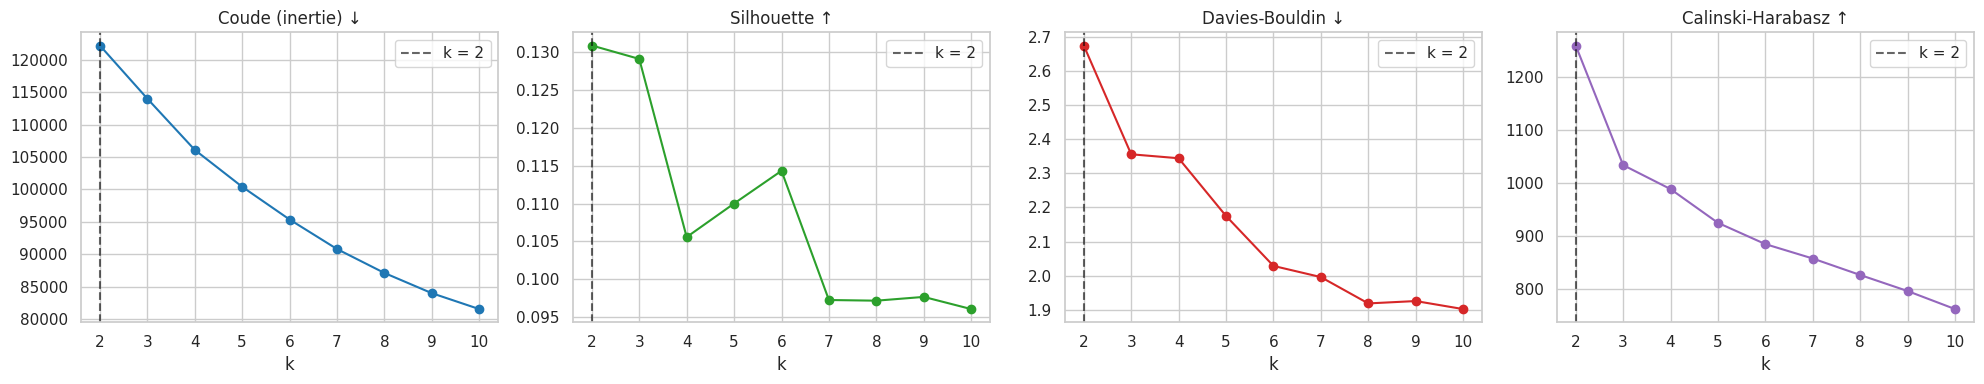

,inertie,silhouette,davies_bouldin,calinski_harabasz
k,,,,
2,122210.0,0.131,2.674,1259.0
3,114017.0,0.129,2.356,1034.0
4,106115.0,0.106,2.344,988.0
5,100421.0,0.110,2.175,925.0
6,95369.0,0.114,2.029,885.0
7,90817.0,0.097,1.996,858.0
8,87125.0,0.097,1.919,827.0
9,84006.0,0.098,1.926,797.0
10,81554.0,0.096,1.903,763.0


In [9]:
from sklearn.cluster import KMeans
from sklearn.metrics import (silhouette_score, silhouette_samples, davies_bouldin_score, calinski_harabasz_score,
                             normalized_mutual_info_score, adjusted_rand_score)

# Échantillon commun (utilisé ici et dans les parties 8 et 9)
rng = np.random.RandomState(RANDOM_STATE)
idx = rng.choice(len(X_pca), size=min(N_SAMPLE, len(X_pca)), replace=False)
Xs = X_pca[idx]
S = clean.iloc[idx].copy()                                  # lignes d'origine correspondantes
coords_s = PCA(n_components=2, random_state=RANDOM_STATE).fit_transform(Xs)   # projection 2D (graphes)

ks = list(range(2, 11))
inertia, sil, dbi, chi = [], [], [], []
for k in ks:
    km_ = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(Xs)
    inertia.append(km_.inertia_)
    sil.append(silhouette_score(Xs, km_.labels_))
    dbi.append(davies_bouldin_score(Xs, km_.labels_))
    chi.append(calinski_harabasz_score(Xs, km_.labels_))

fig, axes = plt.subplots(1, 4, figsize=(20, 4))
for a, y, t, c in zip(axes, [inertia, sil, dbi, chi],
                      ["Coude (inertie) ↓", "Silhouette ↑", "Davies-Bouldin ↓", "Calinski-Harabasz ↑"],
                      ["tab:blue", "tab:green", "tab:red", "tab:purple"]):
    a.plot(ks, y, marker="o", color=c); a.axvline(K, color="black", ls="--", alpha=.6, label=f"k = {K}")
    a.set_title(t); a.set_xlabel("k"); a.legend()
plt.tight_layout(); plt.show()

pd.DataFrame({"k": ks, "inertie": np.round(inertia, 0), "silhouette": np.round(sil, 3),
              "davies_bouldin": np.round(dbi, 3), "calinski_harabasz": np.round(chi, 0)}).set_index("k")

## 7. Clustering final : KMeans avec k = 2

On ajuste KMeans sur **l'ensemble des ~70 000 patients** (dans l'espace PCA), avec 20 initialisations aléatoires (`n_init=20`) pour éviter un mauvais minimum local.

Les clusters sont **renumérotés par taille décroissante** (cluster 0 = le plus grand) pour que la lecture soit stable.

In [10]:
km = KMeans(n_clusters=K, n_init=20, random_state=RANDOM_STATE).fit(X_pca)

# renumérotation par taille décroissante
order = pd.Series(km.labels_).value_counts().index.tolist()
remap = {old: new for new, old in enumerate(order)}
clean["cluster"] = pd.Series(km.labels_, index=clean.index).map(remap)
labels_full = clean["cluster"].values

sizes = clean["cluster"].value_counts().sort_index().to_frame("effectif")
sizes["part_%"] = (sizes["effectif"] / len(clean) * 100).round(1)
display(sizes)

,effectif,part_%
cluster,,
0,43373,62.0
1,26606,38.0


### 7.1 Visualisation des clusters (projection PCA 2D)
La projection sur les 2 premiers axes ne montre qu'une partie de la structure (les autres composantes sont masquées) : un recouvrement visuel n'est donc pas forcément un défaut du clustering. Le second graphique est un **diagramme de silhouette** : chaque barre est un patient, sa longueur mesure à quel point il est « bien rangé » dans son cluster (valeurs négatives = patient plus proche de l'autre cluster).

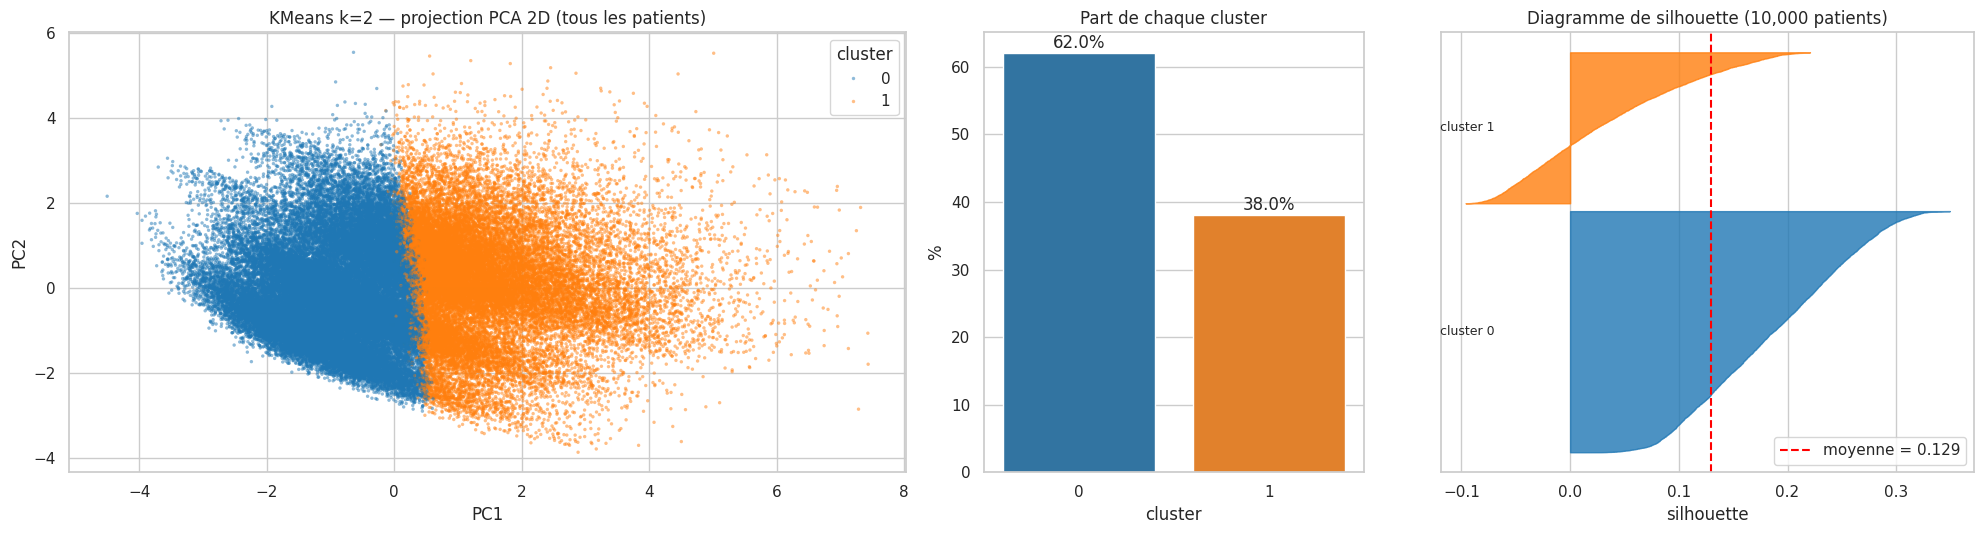

Patients à silhouette négative (probablement mal rangés) : 14.8 %


In [11]:
coords = PCA(n_components=2, random_state=RANDOM_STATE).fit_transform(X)
fig, ax = plt.subplots(1, 3, figsize=(20, 5.5), gridspec_kw={"width_ratios": [2.2, 1, 1.4]})
sns.scatterplot(x=coords[:, 0], y=coords[:, 1], hue=clean["cluster"], palette="tab10", s=6, alpha=.5, linewidth=0, ax=ax[0])
ax[0].set_title(f"KMeans k={K} — projection PCA 2D (tous les patients)"); ax[0].set_xlabel("PC1"); ax[0].set_ylabel("PC2")
sns.barplot(x=sizes.index, y=sizes["part_%"], palette="tab10", ax=ax[1])
for i, v in enumerate(sizes["part_%"]): ax[1].text(i, v + 0.8, f"{v}%", ha="center")
ax[1].set_title("Part de chaque cluster"); ax[1].set_xlabel("cluster"); ax[1].set_ylabel("%")

# diagramme de silhouette sur l'échantillon commun
lab_s = labels_full[idx]
sv = silhouette_samples(Xs, lab_s)
ypos = 0
for c in range(K):
    v = np.sort(sv[lab_s == c])
    ax[2].fill_betweenx(np.arange(ypos, ypos + len(v)), 0, v, color=sns.color_palette("tab10")[c], alpha=.8)
    ax[2].text(-0.12, ypos + len(v) / 2, f"cluster {c}", va="center", fontsize=9)
    ypos += len(v) + 200
ax[2].axvline(sv.mean(), color="red", ls="--", label=f"moyenne = {sv.mean():.3f}")
ax[2].set_title(f"Diagramme de silhouette ({len(Xs):,} patients)"); ax[2].set_xlabel("silhouette"); ax[2].set_yticks([]); ax[2].legend()
plt.tight_layout(); plt.show()
print(f"Patients à silhouette négative (probablement mal rangés) : {(sv < 0).mean()*100:.1f} %")

### 7.2 Profil des clusters — variables numériques et binaires
La **carte de chaleur** affiche les moyennes de chaque cluster (chiffres) ; la couleur indique l'**écart au profil moyen de tous les patients**, exprimé en écarts-types globaux :
`(moyenne du cluster − moyenne globale) / écart-type global`.
Rouge = valeur plus élevée que la moyenne, bleu = plus basse. Un écart > 0,5 est déjà marqué.

> Avec seulement 2 clusters, il serait trompeur de standardiser *entre* les clusters (on obtiendrait toujours ±0,7). On compare donc à la **population globale**.

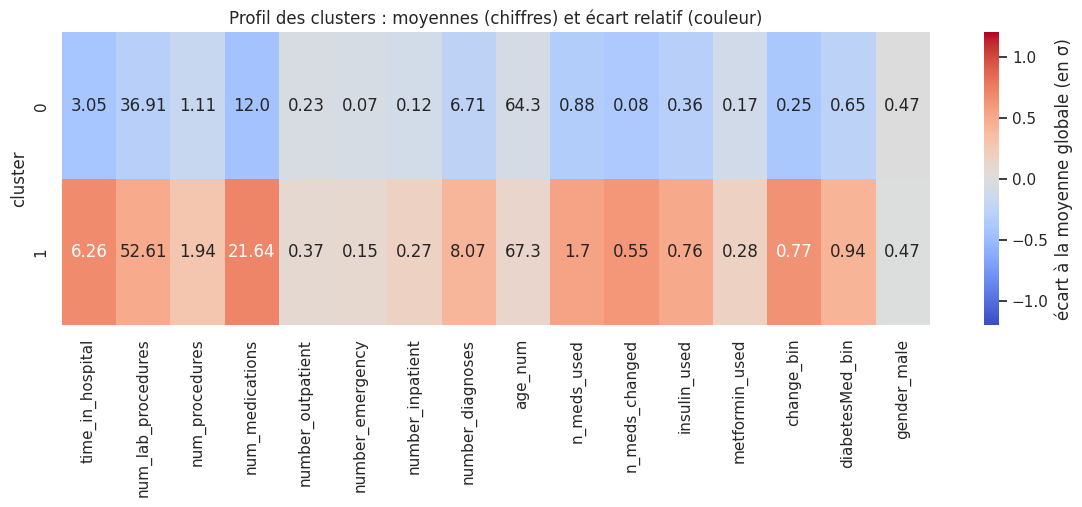

In [12]:
nb_feats = num_feats + bin_feats
prof = clean.groupby("cluster")[nb_feats].mean()
effect = (prof - clean[nb_feats].mean()) / clean[nb_feats].std()

plt.figure(figsize=(14, 0.9 * K + 2))
sns.heatmap(effect, annot=prof.round(2), fmt="", cmap="coolwarm", center=0, vmin=-1.2, vmax=1.2,
            cbar_kws={"label": "écart à la moyenne globale (en σ)"})
plt.title("Profil des clusters : moyennes (chiffres) et écart relatif (couleur)"); plt.ylabel("cluster")
plt.show()

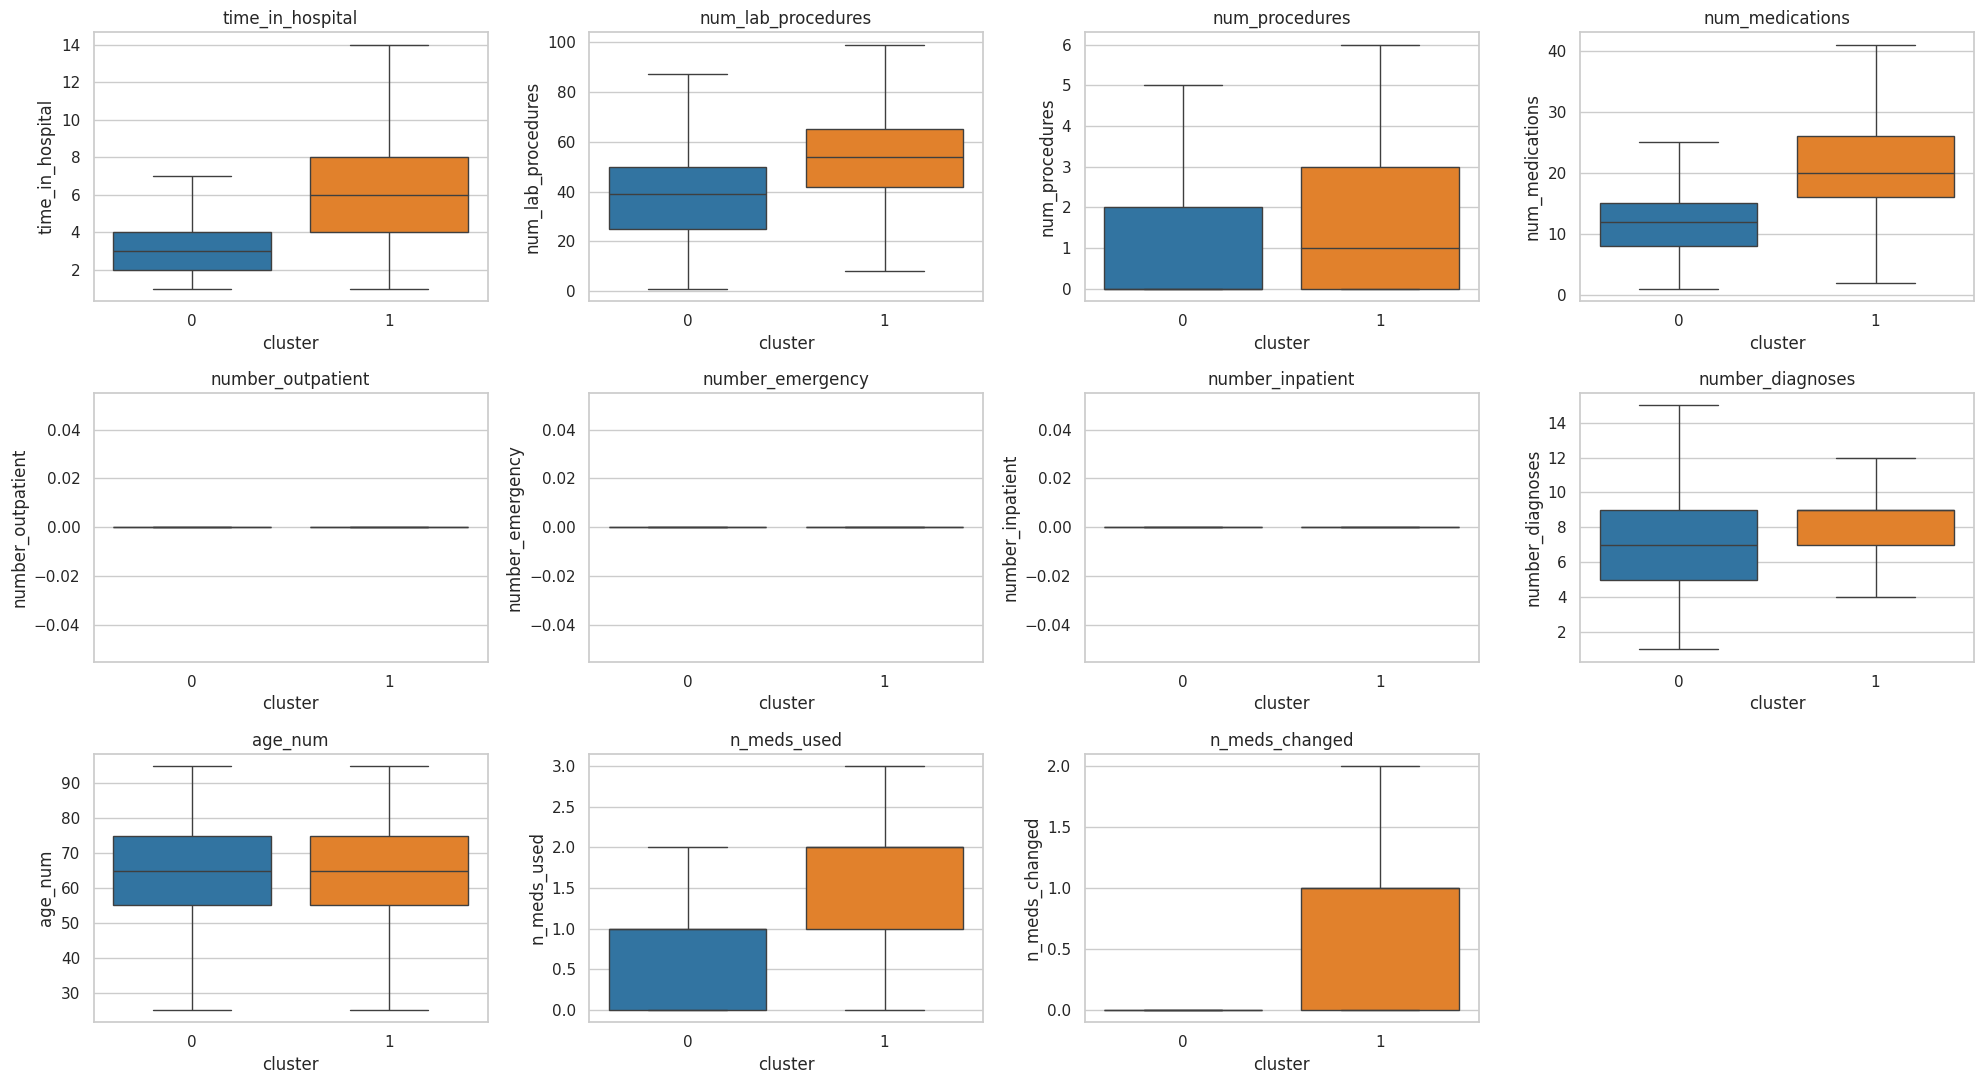

In [13]:
fig, axes = plt.subplots(3, 4, figsize=(20, 11))
for ax, c in zip(axes.ravel(), num_feats):
    sns.boxplot(data=clean, x="cluster", y=c, ax=ax, showfliers=False, palette="tab10")
    ax.set_title(c)
axes.ravel()[-1].axis("off")
plt.tight_layout(); plt.show()

### 7.3 Profil des clusters — variables catégorielles
Chaque barre représente un cluster (100 %) et se découpe selon les modalités de la variable.

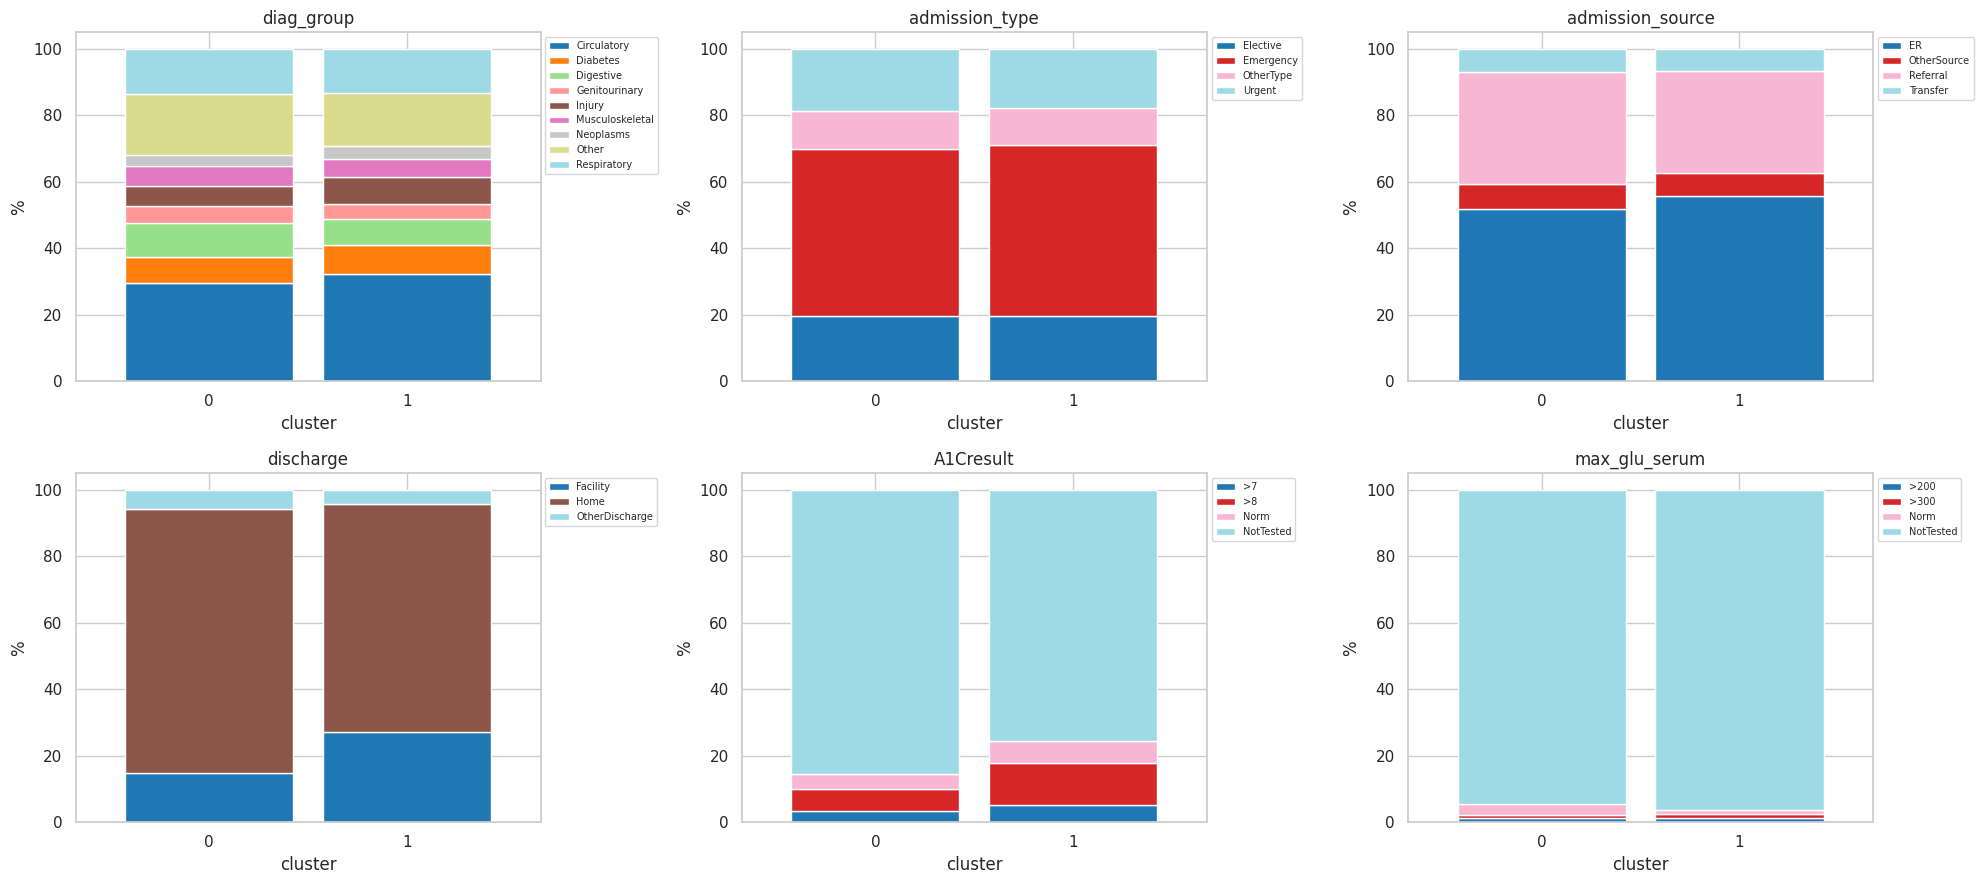

In [14]:
fig, axes = plt.subplots(2, 3, figsize=(20, 9))
for ax, c in zip(axes.ravel(), cat_feats):
    ct = pd.crosstab(clean["cluster"], clean[c], normalize="index") * 100
    ct.plot(kind="bar", stacked=True, ax=ax, width=.85, colormap="tab20")
    ax.set_title(c); ax.set_ylabel("%"); ax.legend(fontsize=7, bbox_to_anchor=(1, 1)); ax.tick_params(axis="x", rotation=0)
plt.tight_layout(); plt.show()

### 7.4 Résumé automatique : ce qui distingue chaque cluster
- **Variables numériques/binaires** : les 5 plus gros écarts à la moyenne globale (en σ).
- **Modalités catégorielles** : celles sur-représentées dans le cluster (*lift* ≥ 1,3 = 30 % de plus que dans la population, et au moins 5 % du cluster).

In [15]:
for c in effect.index:
    print(f"═══ CLUSTER {c}  ({sizes.loc[c, 'effectif']:,} patients, {sizes.loc[c, 'part_%']} %) ═══")
    top = effect.loc[c].reindex(effect.loc[c].abs().sort_values(ascending=False).index).head(5)
    print("  Variables num./bin. les plus marquées :")
    for f, v in top.items():
        print(f"    {f:<20s} {v:+.2f} σ   (moyenne cluster = {prof.loc[c, f]:.2f} | globale = {clean[f].mean():.2f})")
    print("  Modalités sur-représentées :")
    found = False
    for cf in cat_feats:
        share_c = clean.loc[clean["cluster"] == c, cf].value_counts(normalize=True)
        share_g = clean[cf].value_counts(normalize=True)
        for m, s in share_c.items():
            lift = s / share_g[m]
            if lift >= 1.3 and s >= 0.05:
                print(f"    {cf} = {m:<14s} {s*100:5.1f} % du cluster (vs {share_g[m]*100:4.1f} % global, lift x{lift:.2f})"); found = True
    if not found: print("    (aucune)")
    print()

═══ CLUSTER 0  (43,373 patients, 62.0 %) ═══
  Variables num./bin. les plus marquées :
    num_medications      -0.44 σ   (moyenne cluster = 12.00 | globale = 15.67)
    time_in_hospital     -0.42 σ   (moyenne cluster = 3.05 | globale = 4.27)
    change_bin           -0.39 σ   (moyenne cluster = 0.25 | globale = 0.45)
    n_meds_changed       -0.38 σ   (moyenne cluster = 0.08 | globale = 0.26)
    n_meds_used          -0.33 σ   (moyenne cluster = 0.88 | globale = 1.19)
  Modalités sur-représentées :
    (aucune)

═══ CLUSTER 1  (26,606 patients, 38.0 %) ═══
  Variables num./bin. les plus marquées :
    num_medications      +0.72 σ   (moyenne cluster = 21.64 | globale = 15.67)
    time_in_hospital     +0.68 σ   (moyenne cluster = 6.26 | globale = 4.27)
    change_bin           +0.64 σ   (moyenne cluster = 0.77 | globale = 0.45)
    n_meds_changed       +0.61 σ   (moyenne cluster = 0.55 | globale = 0.26)
    n_meds_used          +0.54 σ   (moyenne cluster = 1.70 | globale = 1.19)
  Modal

### 7.5 Modèle de substitution : un arbre de décision pour *expliquer* les clusters
Les clusters vivent dans l'espace PCA, difficile à lire. On entraîne un **arbre de décision peu profond** (profondeur 3) à retrouver le cluster à partir des variables d'origine : ses règles donnent une **description simple** de la frontière entre les 2 groupes. La *fidélité* (accuracy) indique à quel point cette règle simple reproduit le clustering.

Fidélité de l'arbre (validation croisée 5 plis) : 86.4 % des patients retrouvent leur cluster avec 3 questions seulement

|--- num_medications <= 0.10
|   |--- n_meds_changed <= 0.50
|   |   |--- time_in_hospital <= 0.76
|   |   |   |--- weights: [30096.00, 1797.00] class: 0
|   |   |--- time_in_hospital >  0.76
|   |   |   |--- weights: [2019.00, 1417.00] class: 0
|   |--- n_meds_changed >  0.50
|   |   |--- time_in_hospital <= -0.26
|   |   |   |--- weights: [2746.00, 1830.00] class: 0
|   |   |--- time_in_hospital >  -0.26
|   |   |   |--- weights: [584.00, 2907.00] class: 1
|--- num_medications >  0.10
|   |--- change_bin <= 0.50
|   |   |--- time_in_hospital <= 0.42
|   |   |   |--- weights: [5196.00, 1225.00] class: 0
|   |   |--- time_in_hospital >  0.42
|   |   |   |--- weights: [1121.00, 3721.00] class: 1
|   |--- change_bin >  0.50
|   |   |--- time_in_hospital <= -0.26
|   |   |   |--- weights: [1259.00, 2921.00] class: 1
|   |   |--- time_in_hospital >  -0.26
|   |   |   |-

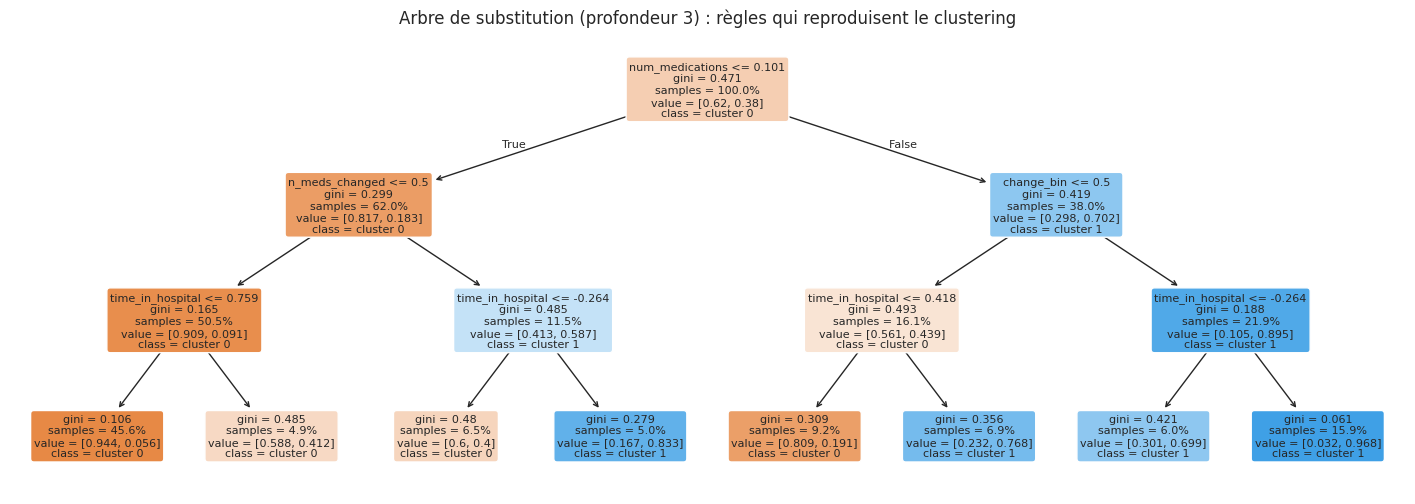

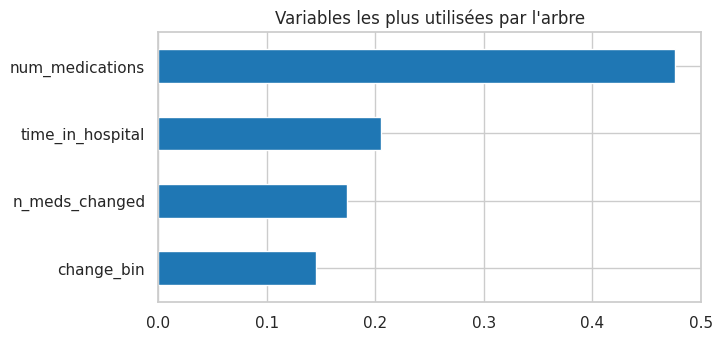

In [16]:
from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree
from sklearn.model_selection import cross_val_score

surrogate = DecisionTreeClassifier(max_depth=3, min_samples_leaf=200, random_state=RANDOM_STATE).fit(X, labels_full)
fid = cross_val_score(DecisionTreeClassifier(max_depth=3, min_samples_leaf=200, random_state=RANDOM_STATE), X, labels_full, cv=5).mean()
print(f"Fidélité de l'arbre (validation croisée 5 plis) : {fid*100:.1f} % des patients retrouvent leur cluster avec 3 questions seulement\n")
print(export_text(surrogate, feature_names=list(X.columns), show_weights=True))

plt.figure(figsize=(18, 6))
plot_tree(surrogate, feature_names=list(X.columns), class_names=[f"cluster {c}" for c in range(K)], filled=True, rounded=True, fontsize=8, proportion=True)
plt.title("Arbre de substitution (profondeur 3) : règles qui reproduisent le clustering"); plt.show()

imp = pd.Series(surrogate.feature_importances_, index=X.columns).sort_values(ascending=False).head(8)
imp[imp > 0].sort_values().plot(kind="barh", color="tab:blue", figsize=(7, 3.5), title="Variables les plus utilisées par l'arbre"); plt.show()

### 7.6 Que perd-on en choisissant k = 2 plutôt que k = 3 ?
k = 2 est le découpage le plus simple, mais il **fusionne** probablement des profils différents. On ajuste KMeans k = 3 sur les mêmes données et on regarde :
1. comment les 3 groupes se répartissent dans les 2 groupes (table croisée, découpage « emboîté » ou non) ;
2. si un groupe à profil spécifique (par exemple des patients très fréquents aux urgences) est **noyé** dans k = 2 ;
3. les métriques côte à côte.

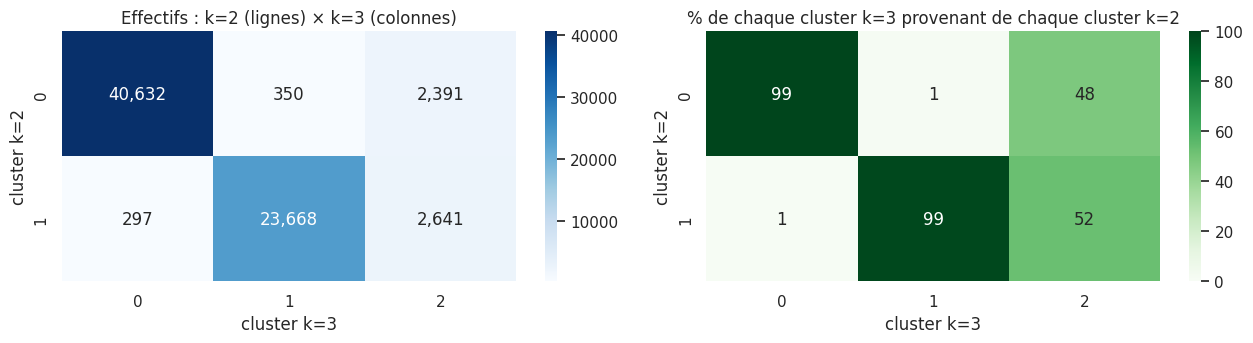

,number_emergency,number_inpatient,number_outpatient,time_in_hospital,num_medications,part_pct
c3,,,,,,
0,0.00,0.12,0.22,3.07,11.99,58.5
1,0.00,0.21,0.30,6.36,21.92,34.3
2,1.43,0.49,0.72,4.13,15.73,7.2


,k = 2 (retenu),k = 3
silhouette,0.130,0.133
davies_bouldin,2.705,2.321
calinski_harabasz,8636.000,7239.000
plus petit cluster (%),38.000,7.200
V de Cramér vs readmitted,0.094,0.085


ARI entre k=2 et k=3 : 0.830


In [17]:
km3 = KMeans(n_clusters=3, n_init=10, random_state=RANDOM_STATE).fit(X_pca)
o3 = pd.Series(km3.labels_).value_counts().index.tolist()
lab3 = pd.Series(km3.labels_).map({old: new for new, old in enumerate(o3)}).values

ct23 = pd.crosstab(pd.Series(labels_full, name="cluster k=2"), pd.Series(lab3, name="cluster k=3"))
fig, ax = plt.subplots(1, 2, figsize=(13, 3.6))
sns.heatmap(ct23, annot=True, fmt=",d", cmap="Blues", ax=ax[0]); ax[0].set_title("Effectifs : k=2 (lignes) × k=3 (colonnes)")
sns.heatmap(pd.crosstab(labels_full, lab3, normalize="columns") * 100, annot=True, fmt=".0f", cmap="Greens", ax=ax[1], vmin=0, vmax=100)
ax[1].set_title("% de chaque cluster k=3 provenant de chaque cluster k=2"); ax[1].set_xlabel("cluster k=3"); ax[1].set_ylabel("cluster k=2")
plt.tight_layout(); plt.show()

# profil du k=3 sur les variables les plus liées aux antécédents d'urgence
p3 = clean.assign(c3=lab3).groupby("c3")[["number_emergency", "number_inpatient", "number_outpatient", "time_in_hospital", "num_medications"]].mean().round(2)
display(p3.assign(part_pct=(pd.Series(lab3).value_counts(normalize=True).sort_index() * 100).round(1).values))

def quick_metrics(lab):
    ss = silhouette_score(X_pca, lab, sample_size=min(15000, len(X_pca)), random_state=RANDOM_STATE)
    tab_ = pd.crosstab(lab, clean["readmitted"]); chi_, _, _, _ = chi2_contingency(tab_)
    return {"silhouette": round(ss, 3), "davies_bouldin": round(davies_bouldin_score(X_pca, lab), 3),
            "calinski_harabasz": round(calinski_harabasz_score(X_pca, lab), 0),
            "plus petit cluster (%)": round(pd.Series(lab).value_counts(normalize=True).min() * 100, 1),
            "V de Cramér vs readmitted": round(np.sqrt(chi_ / (tab_.values.sum() * (min(tab_.shape) - 1))), 3)}
from scipy.stats import chi2_contingency
cmp23 = pd.DataFrame({"k = 2 (retenu)": quick_metrics(labels_full), "k = 3": quick_metrics(lab3)})
display(cmp23)
print(f"ARI entre k=2 et k=3 : {adjusted_rand_score(labels_full, lab3):.3f}")

## 8. Comparaison des algorithmes de clustering (k = 2)

On compare **4 familles d'algorithmes** sur le même échantillon (`Xs`, ≈ 10 000 patients) :

| Famille | Principe | Avantages | Limites |
|---|---|---|---|
| **KMeans** | centres + distance euclidienne | rapide, simple, passe à l'échelle | clusters supposés sphériques et de taille proche |
| **GMM** (mélange gaussien) | clusters = lois normales (forme libre) + probabilités d'appartenance | clusters ellipsoïdaux, affectation souple | sensible à l'initialisation, beaucoup de paramètres en grande dimension |
| **Hiérarchique** (Ward, average, complete) | fusions successives des points les plus proches | dendrogramme, pas d'initialisation | O(n²) en mémoire, sensible aux valeurs extrêmes (average/complete) |
| **DBSCAN** | zones denses séparées par des zones vides ; le reste est du **bruit** | trouve des formes quelconques, détecte les points aberrants | ne permet pas de fixer k ; très sensible à `eps` ; peu efficace en dimension élevée |

**Métriques d'évaluation** (calculées pour chaque modèle) :
- **Silhouette** ↑, **Davies-Bouldin** ↓, **Calinski-Harabasz** ↑ : qualité interne (cohésion/séparation) ;
- **Plus petit cluster (%)** : détecte les solutions dégénérées (un cluster de 0,1 % n'est pas exploitable) ;
- **% bruit** : proportion de points rejetés (DBSCAN) ;
- **ARI vs KMeans** : accord entre le modèle et KMeans k = 2 (1 = partitions identiques, 0 = indépendantes) ;
- **NMI vs readmitted** : information partagée avec la réadmission (validation externe, ↑).

### 8.1 Fonction d'évaluation commune

In [18]:
results = {}      # nom du modèle -> labels
rows = []         # lignes du tableau de comparaison
KM_NAME = f"KMeans k={K}"

def evaluate(name, labels, fit_time=np.nan, family=""):
    labels = np.asarray(labels)
    mask = labels != -1                                     # -1 = bruit (DBSCAN)
    n_cl = len(set(labels[mask]))
    sizes_ = pd.Series(labels[mask]).value_counts(normalize=True) * 100
    row = {"modèle": name, "famille": family, "n_clusters": n_cl,
           "% bruit": round(100 * (~mask).mean(), 1),
           "plus petit cluster (%)": round(sizes_.min(), 1) if len(sizes_) else np.nan,
           "temps (s)": round(fit_time, 1)}
    if n_cl >= 2 and mask.sum() > n_cl:
        row["silhouette"]        = round(silhouette_score(Xs[mask], labels[mask]), 3)
        row["davies_bouldin"]    = round(davies_bouldin_score(Xs[mask], labels[mask]), 3)
        row["calinski_harabasz"] = round(calinski_harabasz_score(Xs[mask], labels[mask]), 0)
        row["NMI vs readmitted"] = round(normalized_mutual_info_score(S["readmitted"].values[mask], labels[mask]), 4)
        if KM_NAME in results:
            ref = results[KM_NAME]
            row["ARI vs KMeans"] = round(adjusted_rand_score(ref[mask], labels[mask]), 3)
    results[name] = labels; rows.append(row)
    return row

### 8.2 KMeans (référence)

In [19]:
t = time.time()
km_s = KMeans(n_clusters=K, n_init=10, random_state=RANDOM_STATE).fit(Xs)
evaluate(KM_NAME, km_s.labels_, time.time() - t, "KMeans")
pd.DataFrame(rows)

,modèle,famille,n_clusters,% bruit,plus petit cluster (%),temps (s),silhouette,davies_bouldin,calinski_harabasz,NMI vs readmitted
0,KMeans k=2,KMeans,2,0.0,37.5,0.1,0.131,2.674,1259.0,0.0073


### 8.3 GMM — mélange gaussien
Le **BIC** (*Bayesian Information Criterion*) pénalise la complexité : plus il est bas, mieux le modèle équilibre ajustement et simplicité. On le calcule pour 4 types de covariance (`spherical` ⊂ `diag` ⊂ `tied`/`full` : de plus en plus flexibles).
Le BIC sert ici d'**information complémentaire** (quel k préférerait le GMM ?), mais on compare à **k = 2** comme pour les autres.

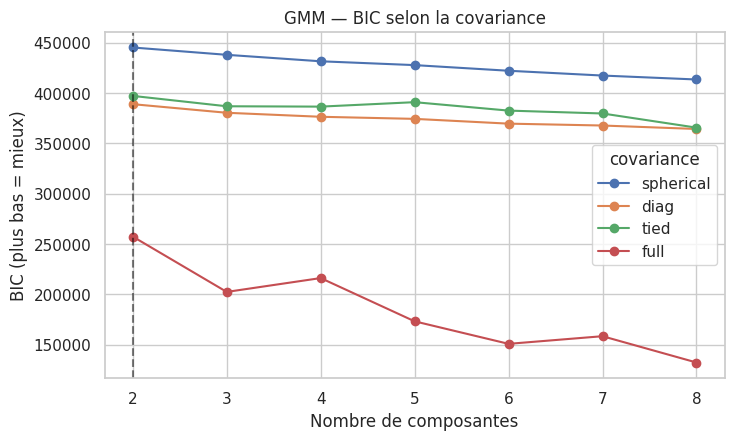

Meilleur BIC global : covariance = full | k = 8
Meilleure covariance à k = 2 : full  (BIC = 257319)
-> le BIC préfère 8 groupes à 2 : normal, il cherche des composantes gaussiennes, pas des segments interprétables.


,spherical,diag,tied,full
k,,,,
2,445240,388924,397144,257319
3,437971,380385,386844,202365
4,431541,376398,386492,216129
5,427738,374322,390916,173151
6,422136,369579,382535,150769
7,417370,367717,379676,158361
8,413452,364289,365606,132233


In [20]:
from sklearn.mixture import GaussianMixture

cov_types = ["spherical", "diag", "tied", "full"]
gks = list(range(2, 9))
bic = {c: [] for c in cov_types}
for c in cov_types:
    for k in gks:
        g = GaussianMixture(n_components=k, covariance_type=c, random_state=RANDOM_STATE, n_init=1, max_iter=150).fit(Xs)
        bic[c].append(g.bic(Xs))

plt.figure(figsize=(8, 4.5))
for c in cov_types: plt.plot(gks, bic[c], marker="o", label=c)
plt.axvline(K, color="black", ls="--", alpha=.5)
plt.xlabel("Nombre de composantes"); plt.ylabel("BIC (plus bas = mieux)"); plt.title("GMM — BIC selon la covariance"); plt.legend(title="covariance")
plt.show()

bic_df = pd.DataFrame(bic, index=gks).rename_axis("k")
best = min(((c, gks[int(np.argmin(bic[c]))], min(bic[c])) for c in cov_types), key=lambda x: x[2])
COV = bic_df.loc[K].idxmin()                                  # meilleure covariance AU k retenu
print(f"Meilleur BIC global : covariance = {best[0]} | k = {best[1]}")
print(f"Meilleure covariance à k = {K} : {COV}  (BIC = {bic_df.loc[K, COV]:.0f})")
print(f"-> le BIC préfère {best[1]} groupes à {K} : normal, il cherche des composantes gaussiennes, pas des segments interprétables.")
bic_df.round(0).astype(int)

In [21]:
# GMM à k = 2 pour chaque type de covariance + la configuration « BIC-optimale » à titre de référence
for cov in cov_types:
    t = time.time()
    g = GaussianMixture(n_components=K, covariance_type=cov, random_state=RANDOM_STATE, n_init=3, max_iter=300).fit(Xs)
    evaluate(f"GMM {cov} k={K}", g.predict(Xs), time.time() - t, "GMM")

t = time.time()
g = GaussianMixture(n_components=best[1], covariance_type=best[0], random_state=RANDOM_STATE, n_init=2, max_iter=300).fit(Xs)
evaluate(f"GMM {best[0]} k={best[1]} (réf. BIC)", g.predict(Xs), time.time() - t, "GMM (réf.)")
pd.DataFrame(rows).tail(5)

,modèle,famille,n_clusters,% bruit,plus petit cluster (%),temps (s),silhouette,davies_bouldin,calinski_harabasz,NMI vs readmitted,ARI vs KMeans
1,GMM spherical k=2,GMM,2,0.0,36.4,0.1,0.145,3.132,965.0,0.0093,0.415
2,GMM diag k=2,GMM,2,0.0,26.8,0.1,0.142,3.481,690.0,0.0189,0.035
3,GMM tied k=2,GMM,2,0.0,25.1,0.3,0.135,2.582,1058.0,0.0026,0.243
4,GMM full k=2,GMM,2,0.0,21.5,0.2,0.169,3.153,750.0,0.0188,0.044
5,GMM full k=8 (réf. BIC),GMM (réf.),8,0.0,5.9,1.5,0.032,3.794,400.0,0.0133,0.072


### 8.4 Clustering hiérarchique
Le **dendrogramme** (sur 400 points pour la lisibilité) montre les fusions successives. Une **grande distance de fusion** entre deux niveaux suggère un bon nombre de clusters : on coupe juste avant ce saut.

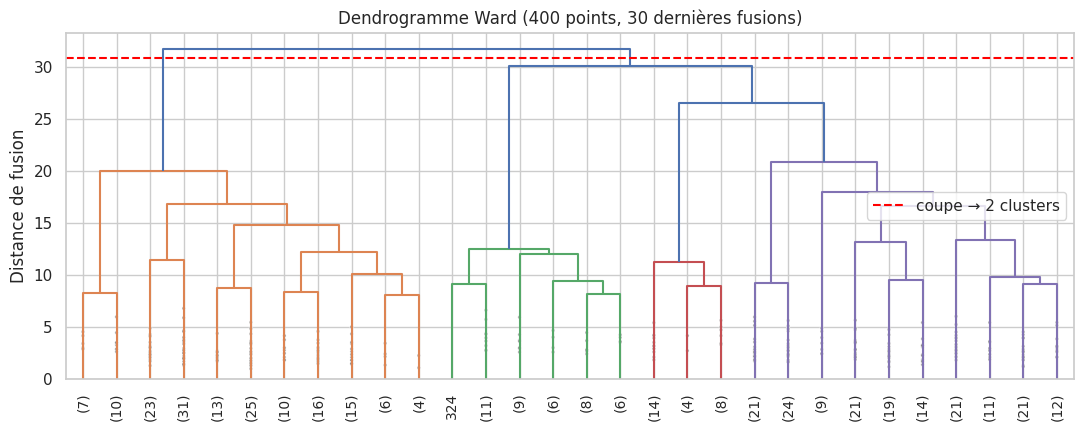

Sauts de distance de fusion (du sommet vers le bas) : [1.66 3.52 5.69 0.88 1.98 1.19 0.14 1.86 1.42]


In [22]:
from scipy.cluster.hierarchy import linkage, dendrogram

small = np.random.RandomState(0).choice(len(Xs), size=min(400, len(Xs)), replace=False)
Z = linkage(Xs[small], method="ward")

plt.figure(figsize=(13, 4.5))
dendrogram(Z, truncate_mode="lastp", p=30, leaf_rotation=90, show_contracted=True)
cut = (Z[-K, 2] + Z[-K + 1, 2]) / 2
plt.axhline(cut, color="red", ls="--", label=f"coupe → {K} clusters"); plt.legend()
plt.title("Dendrogramme Ward (400 points, 30 dernières fusions)"); plt.ylabel("Distance de fusion"); plt.show()

gaps = np.diff(Z[-10:, 2])[::-1]
print("Sauts de distance de fusion (du sommet vers le bas) :", np.round(gaps, 2))

In [23]:
from sklearn.cluster import AgglomerativeClustering

for link in ("ward", "average", "complete"):
    t = time.time()
    ag = AgglomerativeClustering(n_clusters=K, linkage=link).fit(Xs)
    evaluate(f"Hiérarchique {link} k={K}", ag.labels_, time.time() - t, "Hiérarchique")
pd.DataFrame(rows).tail(3)

,modèle,famille,n_clusters,% bruit,plus petit cluster (%),temps (s),silhouette,davies_bouldin,calinski_harabasz,NMI vs readmitted,ARI vs KMeans
6,Hiérarchique ward k=2,Hiérarchique,2,0.0,7.6,4.0,0.232,1.982,755.0,0.0101,0.024
7,Hiérarchique average k=2,Hiérarchique,2,0.0,0.3,4.7,0.460,1.065,117.0,0.0014,0.002
8,Hiérarchique complete k=2,Hiérarchique,2,0.0,7.1,4.6,0.223,1.967,696.0,0.0084,0.017


### 8.5 DBSCAN
DBSCAN a deux paramètres : `eps` (rayon de voisinage) et `min_samples` (nombre minimal de voisins pour former une zone dense). Le **graphe des k-distances** (distance de chaque point à son k-ième plus proche voisin, triée) aide à choisir `eps` : on le prend au « coude ».

DBSCAN ne permet **pas d'imposer k = 2** : on explore une grille de paramètres, on retient une configuration donnant **exactement 2 clusters** si elle existe, sinon la meilleure silhouette parmi les configurations ayant 2 à 8 clusters et ≤ 30 % de bruit.

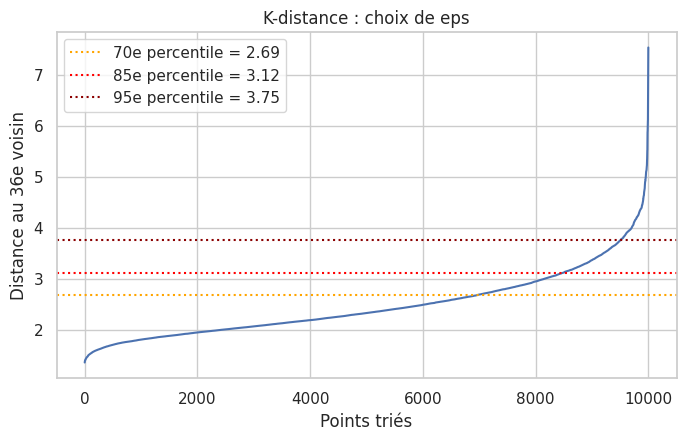

In [24]:
from sklearn.neighbors import NearestNeighbors

MIN_SAMPLES = max(10, 2 * n_comp)                 # règle empirique : ~2 × dimension
dist, _ = NearestNeighbors(n_neighbors=MIN_SAMPLES).fit(Xs).kneighbors(Xs)
kdist = np.sort(dist[:, -1])

plt.figure(figsize=(8, 4.5))
plt.plot(kdist)
for p_, col in zip((70, 85, 95), ("orange", "red", "darkred")):
    plt.axhline(np.percentile(kdist, p_), ls=":", color=col, label=f"{p_}e percentile = {np.percentile(kdist, p_):.2f}")
plt.xlabel("Points triés"); plt.ylabel(f"Distance au {MIN_SAMPLES}e voisin"); plt.title("K-distance : choix de eps"); plt.legend(); plt.show()

In [25]:
from sklearn.cluster import DBSCAN

eps_grid = np.round(np.percentile(kdist, [40, 55, 70, 80, 90, 95]), 2)
ms_grid = [10, 20, MIN_SAMPLES]
grid = []
for eps in eps_grid:
    for ms in ms_grid:
        lab = DBSCAN(eps=float(eps), min_samples=ms).fit_predict(Xs)
        mask = lab != -1
        nc = len(set(lab[mask]))
        s = silhouette_score(Xs[mask], lab[mask]) if nc >= 2 and mask.sum() > nc else np.nan
        grid.append({"eps": eps, "min_samples": ms, "n_clusters": nc, "% bruit": round(100 * (~mask).mean(), 1),
                     "silhouette (hors bruit)": round(s, 3) if s == s else np.nan})
grid = pd.DataFrame(grid)
display(grid)

# sélection : (1) exactement K clusters si possible, (2) sinon meilleure silhouette 2-8 clusters et ≤ 30 % de bruit
exact = grid[(grid["n_clusters"] == K) & (grid["% bruit"] <= 30)].dropna()
ok = grid[(grid["n_clusters"].between(2, 8)) & (grid["% bruit"] <= 30)].dropna()
if len(exact):
    b = exact.sort_values("silhouette (hors bruit)", ascending=False).iloc[0]; why = f"exactement {K} clusters"
elif len(ok):
    b = ok.sort_values("silhouette (hors bruit)", ascending=False).iloc[0];    why = "meilleure silhouette (2-8 clusters)"
else:
    b = None
if b is not None:
    eps_b, ms_b = float(b["eps"]), int(b["min_samples"])
else:
    why = "aucune config satisfaisante → eps au 85e percentile"; eps_b, ms_b = float(np.percentile(kdist, 85)), MIN_SAMPLES
print(f"\nDBSCAN retenu : eps = {eps_b} | min_samples = {ms_b}  ({why})")

t = time.time()
lab_db = DBSCAN(eps=eps_b, min_samples=ms_b).fit_predict(Xs)
DB_NAME = f"DBSCAN eps={eps_b}"
evaluate(DB_NAME, lab_db, time.time() - t, "DBSCAN")
pd.Series(lab_db).value_counts().sort_index().to_frame("taille").rename_axis("cluster (−1 = bruit)")

,eps,min_samples,n_clusters,% bruit,silhouette (hors bruit)
0,2.19,10,6,21.3,0.048
1,2.19,20,4,28.0,-0.026
2,2.19,36,1,34.5,NaN
3,2.41,10,3,13.1,0.142
4,2.41,20,2,18.0,0.129
5,2.41,36,2,22.9,0.098
6,2.69,10,3,6.9,0.148
7,2.69,20,2,9.4,0.158
8,2.69,36,2,12.9,0.132
9,2.95,10,2,3.7,0.189



DBSCAN retenu : eps = 2.95 | min_samples = 10  (exactement 2 clusters)


,taille
cluster (−1 = bruit),
-1,371
0,9088
1,541


### 8.6 Tableau comparatif global
Une solution est jugée **exploitable** si elle a **au moins 2 clusters**, un **plus petit cluster ≥ 2 %** (sinon c'est quasiment un cluster d'aberrants) et **≤ 30 % de bruit**. Le classement (rang moyen sur silhouette, Davies-Bouldin et Calinski-Harabasz) ne porte que sur les solutions exploitables à k = 2 (les lignes de référence — BIC et DBSCAN à k libre — sont affichées mais pas classées).

In [26]:
comp = pd.DataFrame(rows).drop_duplicates("modèle").set_index("modèle")
comp["exploitable"] = (comp["n_clusters"] >= 2) & (comp["plus petit cluster (%)"] >= 2) & (comp["% bruit"] <= 30)

cand = comp[(comp["exploitable"]) & (comp["n_clusters"] == K) & (~comp["famille"].str.contains("réf"))].copy()
cand["rang_sil"] = cand["silhouette"].rank(ascending=False)
cand["rang_dbi"] = cand["davies_bouldin"].rank(ascending=True)
cand["rang_chi"] = cand["calinski_harabasz"].rank(ascending=False)
cand["rang_moyen"] = cand[["rang_sil", "rang_dbi", "rang_chi"]].mean(axis=1)
comp["rang_moyen"] = cand["rang_moyen"]

cols = ["famille", "n_clusters", "% bruit", "plus petit cluster (%)", "silhouette", "davies_bouldin",
        "calinski_harabasz", "ARI vs KMeans", "NMI vs readmitted", "temps (s)", "exploitable", "rang_moyen"]
comp_sorted = comp[cols].sort_values(["exploitable", "rang_moyen"], ascending=[False, True])
display(comp_sorted)

,famille,n_clusters,% bruit,plus petit cluster (%),silhouette,davies_bouldin,calinski_harabasz,ARI vs KMeans,NMI vs readmitted,temps (s),exploitable,rang_moyen
modèle,,,,,,,,,,,,
Hiérarchique ward k=2,Hiérarchique,2,0.0,7.6,0.232,1.982,755.0,0.024,0.0101,4.0,True,2.333333
Hiérarchique complete k=2,Hiérarchique,2,0.0,7.1,0.223,1.967,696.0,0.017,0.0084,4.6,True,3.000000
GMM tied k=2,GMM,2,0.0,25.1,0.135,2.582,1058.0,0.243,0.0026,0.3,True,4.333333
KMeans k=2,KMeans,2,0.0,37.5,0.131,2.674,1259.0,NaN,0.0073,0.1,True,4.666667
GMM spherical k=2,GMM,2,0.0,36.4,0.145,3.132,965.0,0.415,0.0093,0.1,True,4.666667
DBSCAN eps=2.95,DBSCAN,2,3.7,5.6,0.189,1.996,486.0,0.010,0.0055,0.5,True,4.666667
GMM full k=2,GMM,2,0.0,21.5,0.169,3.153,750.0,0.044,0.0188,0.2,True,5.333333
GMM diag k=2,GMM,2,0.0,26.8,0.142,3.481,690.0,0.035,0.0189,0.1,True,7.000000
GMM full k=8 (réf. BIC),GMM (réf.),8,0.0,5.9,0.032,3.794,400.0,0.072,0.0133,1.5,True,NaN


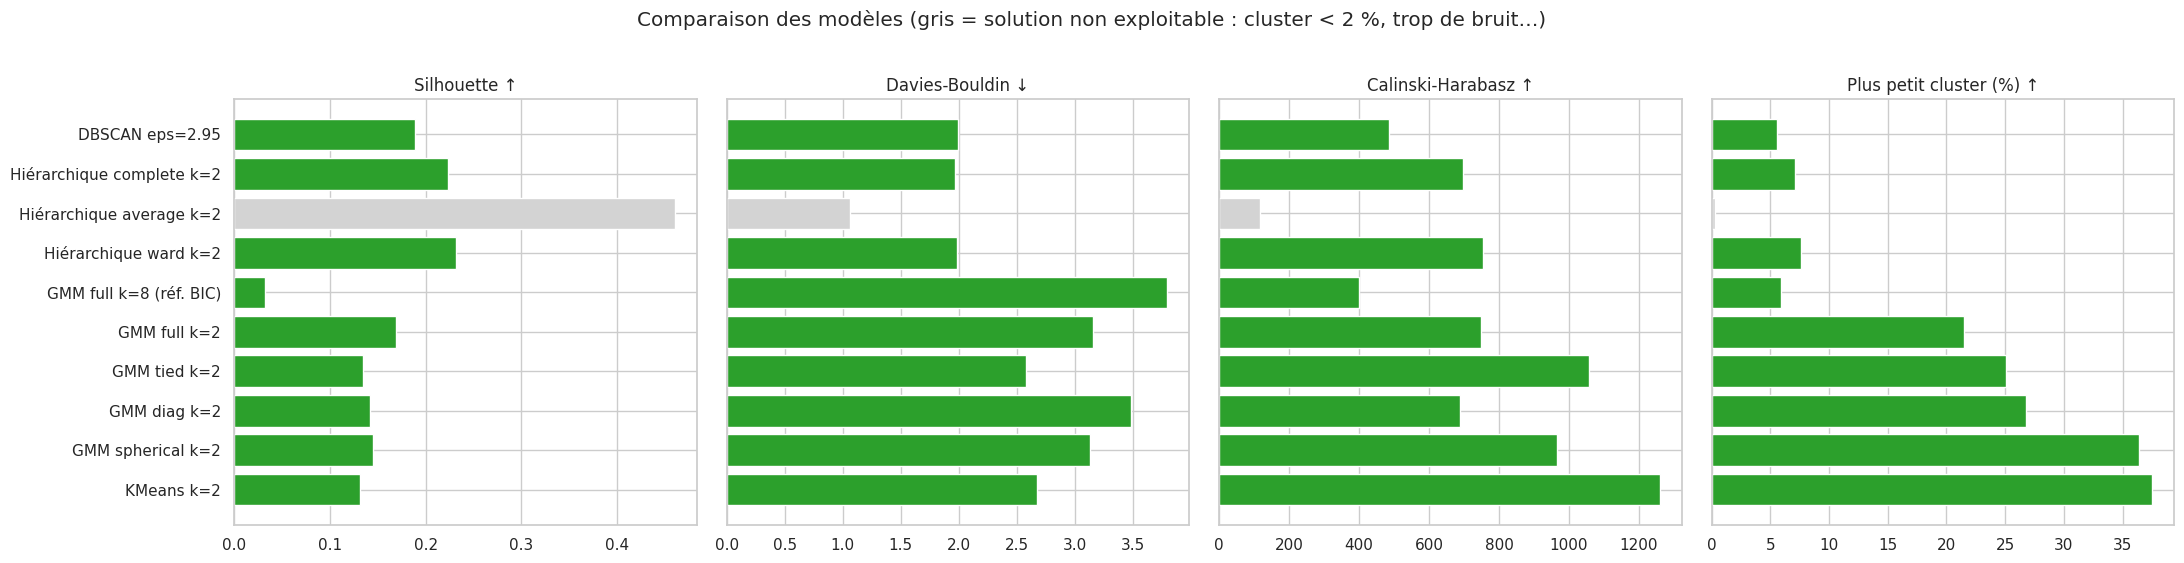

In [27]:
c = comp.dropna(subset=["silhouette"]).copy()
colors = ["tab:green" if e else "lightgray" for e in c["exploitable"]]      # gris = solution non exploitable
fig, ax = plt.subplots(1, 4, figsize=(22, 5.5))
for a, col, t in zip(ax, ["silhouette", "davies_bouldin", "calinski_harabasz", "plus petit cluster (%)"],
                     ["Silhouette ↑", "Davies-Bouldin ↓", "Calinski-Harabasz ↑", "Plus petit cluster (%) ↑"]):
    a.barh(c.index, c[col], color=colors); a.set_title(t)
for a in ax[1:]: a.set_yticklabels([])
plt.suptitle("Comparaison des modèles (gris = solution non exploitable : cluster < 2 %, trop de bruit…)", y=1.02)
plt.tight_layout(); plt.show()

### 8.7 Visualisation des partitions (PCA 2D de l'échantillon)

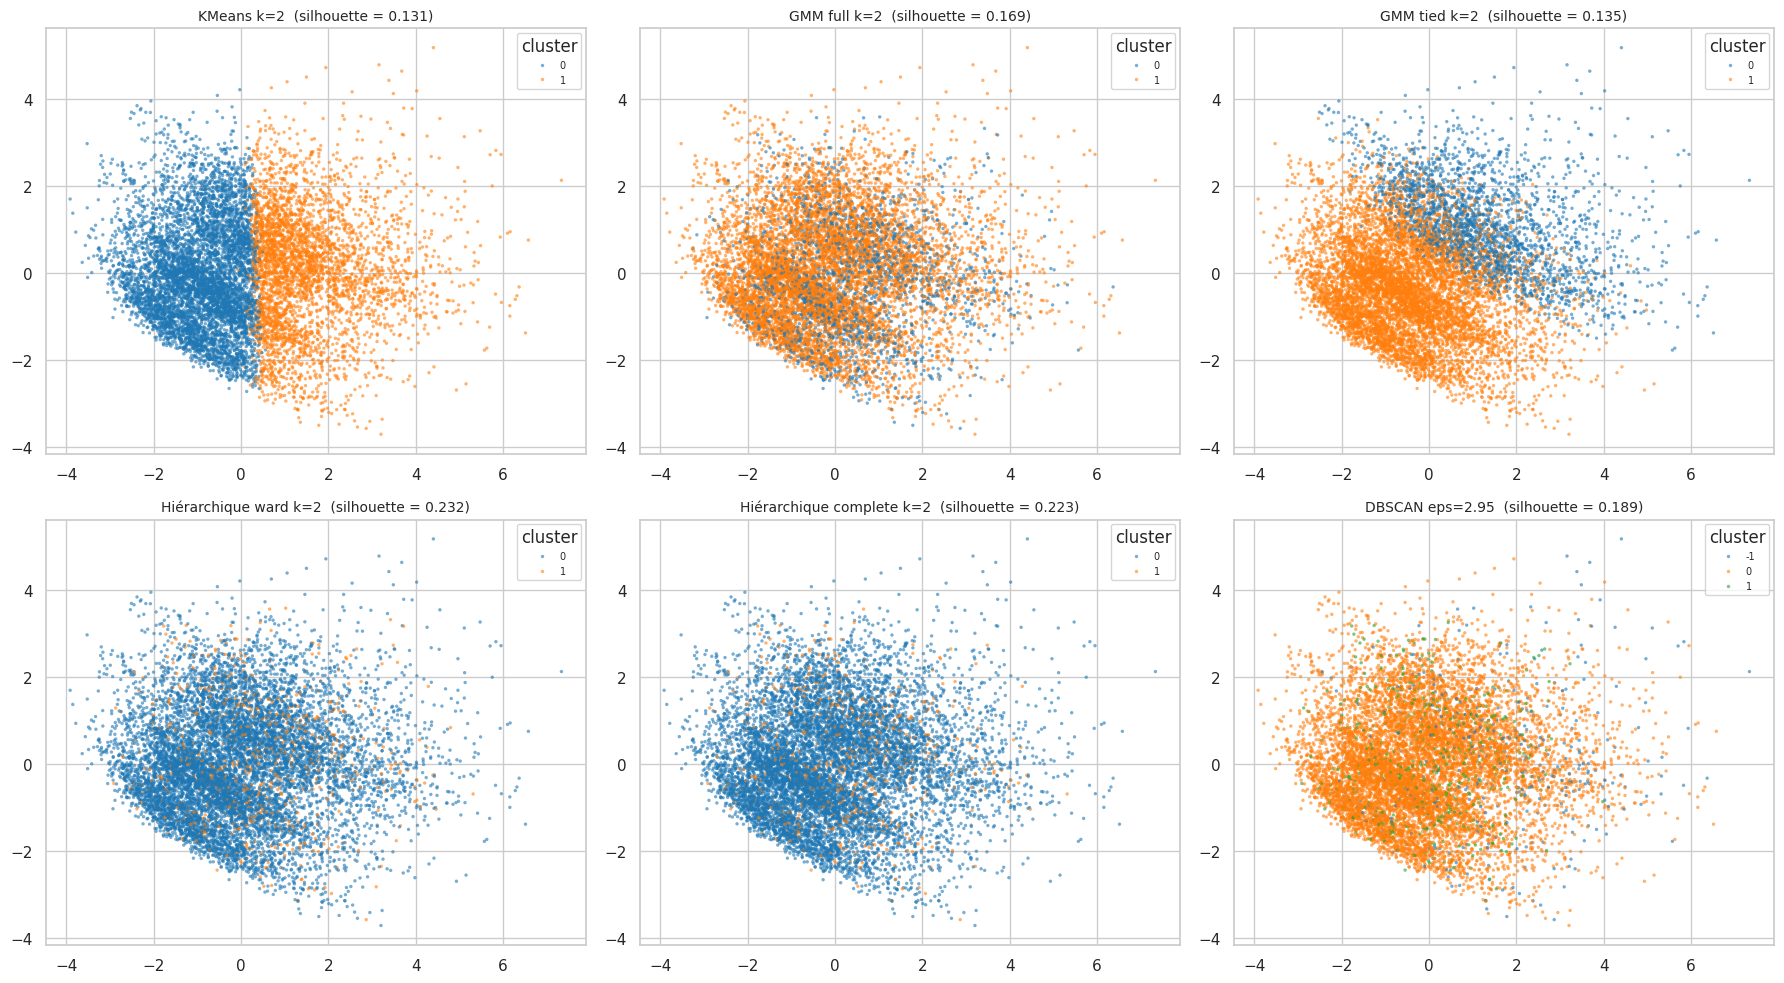

In [28]:
show = [KM_NAME, f"GMM full k={K}", f"GMM tied k={K}", f"Hiérarchique ward k={K}", f"Hiérarchique complete k={K}", DB_NAME]
show = [m for m in show if m in results]
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
for ax, name in zip(axes.ravel(), show):
    sns.scatterplot(x=coords_s[:, 0], y=coords_s[:, 1], hue=results[name], palette="tab10", s=6, alpha=.6, linewidth=0, ax=ax, legend="full")
    sil_ = comp.loc[name, "silhouette"] if name in comp.index else np.nan
    ax.set_title(f"{name}  (silhouette = {sil_})", fontsize=10); ax.legend(title="cluster", fontsize=7)
for ax in axes.ravel()[len(show):]: ax.axis("off")
plt.tight_layout(); plt.show()

### 8.8 Quel algorithme retenir ? — stabilité du KMeans k = 2
En plus des métriques ci-dessus, un bon clustering doit être **stable** : si on relance l'algorithme avec une autre graine ou sur un sous-échantillon, on doit retrouver les mêmes groupes. On mesure l'accord avec l'**ARI** (Adjusted Rand Index : 1 = partitions identiques, 0 = indépendantes) par rapport à la partition finale :
- **graines** : 10 lancements de KMeans (`n_init=10` chacun) avec des graines différentes ;
- **sous-échantillonnage** : KMeans ajusté sur 80 % des patients tirés au hasard (`n_init=10`), puis affectation de tous les patients.

On compte aussi la part des lancements qui **retrouvent la même partition** (ARI ≥ 0,9) : KMeans peut converger vers des **minima locaux** différents, d'où l'intérêt de `n_init` élevé.

In [29]:
# Stabilité aux graines
ari_seeds, inert_seeds = [], []
for s in range(10):
    m_ = KMeans(n_clusters=K, n_init=10, random_state=100 + s).fit(X_pca)
    ari_seeds.append(adjusted_rand_score(labels_full, m_.labels_)); inert_seeds.append(m_.inertia_)

# Stabilité au sous-échantillonnage (80 %)
ari_boot = []
rs = np.random.RandomState(7)
for _ in range(10):
    sub = rs.choice(len(X_pca), size=int(0.8 * len(X_pca)), replace=False)
    lab = KMeans(n_clusters=K, n_init=10, random_state=RANDOM_STATE).fit(X_pca[sub]).predict(X_pca)
    ari_boot.append(adjusted_rand_score(labels_full, lab))

pct_seeds = 100 * np.mean(np.array(ari_seeds) >= 0.9)
pct_boot  = 100 * np.mean(np.array(ari_boot) >= 0.9)
stab = pd.DataFrame({"ARI moyen": [np.mean(ari_seeds), np.mean(ari_boot)],
                     "ARI min": [np.min(ari_seeds), np.min(ari_boot)],
                     "% de runs retrouvant la partition (ARI ≥ 0,9)": [pct_seeds, pct_boot]},
                    index=["10 graines différentes", "10 sous-échantillons (80 %)"]).round(3)
display(stab)

detail = pd.DataFrame({"ARI vs solution finale": np.round(ari_seeds, 3), "inertie": np.round(inert_seeds, 0)},
                      index=[f"graine {100 + s}" for s in range(10)]).T
display(detail)
print(f"Inertie de la solution finale (n_init=20) : {km.inertia_:,.0f}")

,ARI moyen,ARI min,"% de runs retrouvant la partition (ARI ≥ 0,9)"
10 graines différentes,0.990,0.986,100.0
10 sous-échantillons (80 %),0.988,0.976,100.0


,graine 100,graine 101,graine 102,graine 103,graine 104,graine 105,graine 106,graine 107,graine 108,graine 109
ARI vs solution finale,0.989,0.988,0.991,0.986,0.986,0.991,0.997,0.996,0.989,0.991
inertie,847688.000,847687.000,847687.000,847688.000,847688.000,847687.000,847686.000,847687.000,847687.000,847686.000


Inertie de la solution finale (n_init=20) : 847,686


### 8.9 Lecture automatique de la comparaison
Cette cellule résume les résultats **calculés ci-dessus** (elle s'adapte si tu relances avec une autre graine ou un autre `N_SAMPLE`).

In [30]:
expl = comp_sorted[comp_sorted["exploitable"] == True]
bad  = comp_sorted[comp_sorted["exploitable"] == False]
print("SOLUTIONS EXPLOITABLES (classées par rang moyen) :")
for name, r in expl.iterrows():
    if pd.notna(r["rang_moyen"]):
        print(f"  {r['rang_moyen']:.2f}  {name:<32s} silhouette={r['silhouette']}  DB={r['davies_bouldin']}  CH={r['calinski_harabasz']:.0f}  plus petit cluster={r['plus petit cluster (%)']} %")
print("\nSOLUTIONS NON EXPLOITABLES (à ne pas retenir malgré d'éventuels bons scores) :")
for name, r in bad.iterrows():
    reasons = []
    if r["n_clusters"] < 2: reasons.append("moins de 2 clusters")
    if r["plus petit cluster (%)"] < 2: reasons.append(f"plus petit cluster = {r['plus petit cluster (%)']} %")
    if r["% bruit"] > 30: reasons.append(f"{r['% bruit']} % de bruit")
    print(f"  - {name:<32s} silhouette={r.get('silhouette')}  → {', '.join(reasons)}")

sil_expl = expl["silhouette"].dropna()
print(f"\nSilhouettes des solutions exploitables : de {sil_expl.min():.3f} à {sil_expl.max():.3f}")
print("→ structure", "faible : les patients forment plutôt un continuum que des groupes séparés." if sil_expl.max() < 0.25 else "modérée à forte.")
print(f"Stabilité de KMeans k={K} : ARI moyen {np.mean(ari_seeds):.3f} (graines) / {np.mean(ari_boot):.3f} (sous-échantillons)")

SOLUTIONS EXPLOITABLES (classées par rang moyen) :
  2.33  Hiérarchique ward k=2            silhouette=0.232  DB=1.982  CH=755  plus petit cluster=7.6 %
  3.00  Hiérarchique complete k=2        silhouette=0.223  DB=1.967  CH=696  plus petit cluster=7.1 %
  4.33  GMM tied k=2                     silhouette=0.135  DB=2.582  CH=1058  plus petit cluster=25.1 %
  4.67  KMeans k=2                       silhouette=0.131  DB=2.674  CH=1259  plus petit cluster=37.5 %
  4.67  GMM spherical k=2                silhouette=0.145  DB=3.132  CH=965  plus petit cluster=36.4 %
  4.67  DBSCAN eps=2.95                  silhouette=0.189  DB=1.996  CH=486  plus petit cluster=5.6 %
  5.33  GMM full k=2                     silhouette=0.169  DB=3.153  CH=750  plus petit cluster=21.5 %
  7.00  GMM diag k=2                     silhouette=0.142  DB=3.481  CH=690  plus petit cluster=26.8 %

SOLUTIONS NON EXPLOITABLES (à ne pas retenir malgré d'éventuels bons scores) :
  - Hiérarchique average k=2         silhouett

## 9. Méthodes pour variables mixtes et notation /10

Les parties précédentes travaillent dans l'espace **PCA** (variables transformées). Or le jeu de données mélange des variables numériques, binaires et catégorielles. On ajoute donc deux approches pensées pour ce cas, et on compare **5 méthodes** au même `K = 2` avec une **note /10** :

| # | Méthode | Espace de travail | Données utilisées |
|---|---------|-------------------|-------------------|
| 1 | **K-Means** (référence) | PCA | toutes les lignes |
| 2 | **GMM** (covariance choisie par BIC en 8.3) | PCA | toutes les lignes |
| 3 | **Ward** (hiérarchique) | PCA | **sous-échantillon** (Ward est en O(n²)), puis extension aux autres lignes par plus proches voisins |
| 4 | **K-Prototypes** (numérique + catégoriel) | variables *originales* (num. standardisées + catégories brutes) | toutes les lignes |
| 5 | **Gower + K-Medoids** | distance de Gower | **sous-échantillon** (matrice n×n), puis extension par distance au médoïde |

> K-Prototypes et Gower sont codés en NumPy ci-dessous (pas besoin de `kmodes` ni de `gower`).
> `readmitted` n'est **jamais** utilisée pour construire les clusters, seulement pour les évaluer.

### 9.1 Outils : Gower, K-Prototypes, K-Medoids
- **Gower** : distance moyenne par variable — |Δ|/étendue pour les numériques, 0/1 (égal / différent) pour les catégorielles.
- **K-Prototypes** (Huang) : coût = Σ(écart numérique)² + γ · (nb. de catégories différentes), centre = moyenne (num.) + mode (cat.). γ = 0,5 (valeur usuelle pour des numériques standardisées).
- **K-Medoids** sur matrice de Gower : le centre est un vrai patient (médoïde).

In [31]:
from itertools import combinations
from sklearn.neighbors import KNeighborsClassifier

N = len(X_pca)
rng_ext = np.random.RandomState(RANDOM_STATE)
WARD_N   = min(8000, N)      # taille du sous-échantillon Ward
PAM_N    = min(4000, N)      # taille du sous-échantillon Gower / K-Medoids
eval_idx = rng_ext.choice(N, size=min(3000, N), replace=False)   # sous-échantillon d'évaluation commun (silhouette Gower)
print(f"N = {N} | K = {K} | Ward sur {WARD_N} lignes | Gower sur {PAM_N} lignes")

# ---------- représentation "mixte" des données ----------
Xn_mix = X_num.to_numpy(float)
mix_cat_cols = bin_feats + cat_feats
Xc_mix = np.column_stack([pd.factorize(clean[c])[0] for c in mix_cat_cols]).astype(int)

G_num = clean[num_feats].copy(); G_num[skewed] = np.log1p(G_num[skewed]); G_num = G_num.to_numpy(float)
G_rng = G_num.max(0) - G_num.min(0); G_rng[G_rng == 0] = 1

def gower(ia, ib):
    "Matrice de distance de Gower entre les lignes ia et ib."
    D = np.zeros((len(ia), len(ib)))
    for j in range(G_num.shape[1]):
        D += np.abs(G_num[ia, j][:, None] - G_num[ib, j][None, :]) / G_rng[j]
    for j in range(Xc_mix.shape[1]):
        D += (Xc_mix[ia, j][:, None] != Xc_mix[ib, j][None, :])
    return D / (G_num.shape[1] + Xc_mix.shape[1])

# ---------- K-Prototypes ----------
GAMMA = 0.5
def _kp_dist(Xn, Xc, cn, cc):
    d = np.zeros((len(Xn), len(cn)))
    for c in range(len(cn)):
        d[:, c] = ((Xn - cn[c]) ** 2).sum(1) + GAMMA * (Xc != cc[c]).sum(1)
    return d

def kprototypes(Xn, Xc, k, n_init=3, max_iter=25, seed=0):
    r, best = np.random.RandomState(seed), None
    for _ in range(n_init):
        init = r.choice(len(Xn), k, replace=False)
        cn, cc, lab = Xn[init].copy(), Xc[init].copy(), None
        for _ in range(max_iter):
            d = _kp_dist(Xn, Xc, cn, cc); new = d.argmin(1)
            if lab is not None and (new == lab).all(): break
            lab = new
            for c in range(k):
                m = lab == c
                if m.any():
                    cn[c] = Xn[m].mean(0)
                    cc[c] = [np.bincount(Xc[m, j]).argmax() for j in range(Xc.shape[1])]
        cost = _kp_dist(Xn, Xc, cn, cc).min(1).sum()
        if best is None or cost < best[0]: best = (cost, cn, cc)
    return best[1], best[2]

# ---------- K-Medoids sur matrice de Gower ----------
def kmedoids(D, k, n_init=5, max_iter=30, seed=0):
    r, best = np.random.RandomState(seed), None
    for _ in range(n_init):
        med = [r.randint(len(D))]
        for _ in range(k - 1):                                   # init type k-means++
            p = D[:, med].min(1) ** 2; med.append(r.choice(len(D), p=p / p.sum()))
        med = np.array(med)
        for _ in range(max_iter):
            lab = D[:, med].argmin(1); new = med.copy()
            for c in range(k):
                m = np.where(lab == c)[0]
                if len(m): new[c] = m[D[np.ix_(m, m)].sum(1).argmin()]
            if (new == med).all(): break
            med = new
        cost = D[:, med].min(1).sum()
        if best is None or cost < best[0]: best = (cost, med)
    return best[1]

N = 69979 | K = 2 | Ward sur 8000 lignes | Gower sur 4000 lignes


### 9.2 Ajustement des 5 modèles
Chaque `fit_*` prend des indices d'apprentissage et renvoie une fonction `predict(indices)`. Cela permet d'**étendre** Ward et Gower (ajustés sur un sous-échantillon) à toutes les lignes, et de mesurer la **stabilité** plus bas.

In [32]:
def fit_kmeans(tr, seed=0, n_init=10):
    m = KMeans(K, n_init=n_init, random_state=seed).fit(X_pca[tr]); return lambda ix: m.predict(X_pca[ix])

def fit_gmm(tr, seed=0, n_init=3):
    m = GaussianMixture(K, covariance_type=COV, n_init=n_init, random_state=seed).fit(X_pca[tr]); return lambda ix: m.predict(X_pca[ix])

def fit_ward(tr, seed=0):
    lab = AgglomerativeClustering(n_clusters=K, linkage="ward").fit_predict(X_pca[tr])
    knn = KNeighborsClassifier(15).fit(X_pca[tr], lab); return lambda ix: knn.predict(X_pca[ix])

def fit_kproto(tr, seed=0, n_init=3):
    cn, cc = kprototypes(Xn_mix[tr], Xc_mix[tr], K, n_init=n_init, seed=seed)
    return lambda ix: _kp_dist(Xn_mix[ix], Xc_mix[ix], cn, cc).argmin(1)

def fit_gower(tr, seed=0):
    med = tr[kmedoids(gower(tr, tr), K, seed=seed)]
    return lambda ix: np.concatenate([gower(ix[i:i+5000], med).argmin(1) for i in range(0, len(ix), 5000)])

ALL = np.arange(N)
# (fonction, indices d'apprentissage pour l'ajustement final, taille d'apprentissage pour le test de stabilité)
METHODS = {
    "K-Means":              (fit_kmeans, ALL,                                                  N // 2),
    "GMM (BIC)":            (fit_gmm,    ALL,                                                  N // 2),
    "Ward (sous-éch.)":     (fit_ward,   rng_ext.choice(N, WARD_N, replace=False),             min(4000, N)),
    "K-Prototypes":         (fit_kproto, ALL,                                                  N // 2),
    "Gower + K-Medoids":    (fit_gower,  rng_ext.choice(N, PAM_N,  replace=False),             min(3000, N)),
}
labels_ext, predictors, fit_time = {}, {}, {}
for name, (fit, tr, _) in METHODS.items():
    t0 = time.time(); predictors[name] = fit(tr); labels_ext[name] = predictors[name](ALL); fit_time[name] = time.time() - t0
    print(f"{name:20s} {fit_time[name]:6.1f}s   tailles :", np.bincount(labels_ext[name], minlength=K).tolist())

K-Means                 0.6s   tailles : [43363, 26616]


GMM (BIC)               2.8s   tailles : [44168, 25811]


Ward (sous-éch.)        5.6s   tailles : [32140, 37839]


K-Prototypes            2.9s   tailles : [27109, 42870]


Gower + K-Medoids       2.3s   tailles : [42415, 27564]


### 9.3 Mesures objectives
- **Silhouette (PCA)** et **Davies-Bouldin** : qualité géométrique dans l'espace PCA (favorise K-Means / Ward / GMM).
- **Silhouette (Gower)** : qualité dans l'espace des variables *originales* mixtes (favorise K-Prototypes / Gower) — l'avoir à côté de la précédente évite un classement biaisé.
- **Stabilité** : ARI moyen entre 3 ajustements sur des sous-échantillons différents, évalués sur les mêmes lignes (1 = identique).
- **Équilibre** : entropie normalisée des tailles de clusters (1 = parfaitement équilibré, ~0 = un cluster avale tout).
- **Lien avec la réadmission** : V de Cramér (clusters × `readmitted`), validation externe.

In [33]:
D_eval = gower(eval_idx, eval_idx)
readm = clean["readmitted"].values

def cramers_v(a, b):
    ct = pd.crosstab(a, b); chi2_ = chi2_contingency(ct)[0]
    return np.sqrt(chi2_ / (ct.values.sum() * (min(ct.shape) - 1)))

rows_ext = []
for name, (fit, tr, stab_n) in METHODS.items():
    lab = labels_ext[name]
    runs = [fit(np.random.RandomState(s).choice(N, stab_n, replace=False), seed=s)(eval_idx) for s in (1, 2, 3)]
    stab_ = np.mean([adjusted_rand_score(a, b) for a, b in combinations(runs, 2)])
    p = np.bincount(lab, minlength=K) / N; p = p[p > 0]
    rows_ext.append({
        "méthode": name,
        "silhouette_PCA":   silhouette_score(X_pca[idx], lab[idx]),
        "davies_bouldin":   davies_bouldin_score(X_pca[idx], lab[idx]),
        "silhouette_Gower": silhouette_score(D_eval, lab[eval_idx], metric="precomputed"),
        "stabilité_ARI":    stab_,
        "équilibre":        -(p * np.log(p)).sum() / np.log(K),
        "V_Cramér_réadm":   cramers_v(lab, readm),
        "temps_s":          fit_time[name],
    })
metrics = pd.DataFrame(rows_ext).set_index("méthode")
metrics.round(3)

,silhouette_PCA,davies_bouldin,silhouette_Gower,stabilité_ARI,équilibre,V_Cramér_réadm,temps_s
méthode,,,,,,,
K-Means,0.129,2.685,0.112,0.982,0.958,0.093,0.557
GMM (BIC),0.121,3.230,0.084,0.933,0.950,0.124,2.799
Ward (sous-éch.),0.095,3.417,0.060,0.264,0.995,0.133,5.553
K-Prototypes,0.128,2.694,0.108,0.971,0.963,0.094,2.883
Gower + K-Medoids,0.076,3.078,0.229,0.618,0.967,0.040,2.276


### 9.4 Notes /10
Chaque critère est converti en note de 0 à 10 par une échelle **fixée à l'avance** (pas relative au meilleur du lot), puis pondérée.

| Critère | Poids | 0 point | 10 points |
|---|---|---|---|
| Silhouette (PCA) | 15 % | ≤ 0 | ≥ 0,35 |
| Silhouette (Gower) | 15 % | ≤ 0 | ≥ 0,30 |
| Davies-Bouldin | 10 % | ≥ 3 | ≤ 1 |
| Stabilité (ARI) | 20 % | 0 | 1 |
| Équilibre des tailles | 10 % | 0 | 1 |
| Lien réadmission (V de Cramér) | 20 % | 0 | ≥ 0,10 |
| Temps de calcul (échelle log) | 10 % | ≥ 300 s | ≤ 1 s |

,silhouette_PCA,silhouette_Gower,davies_bouldin,stabilité_ARI,équilibre,V_Cramér_réadm,temps_s,NOTE /10
méthode,,,,,,,,
K-Means,3.7,3.7,1.6,9.8,9.6,9.3,10.0,7.1
K-Prototypes,3.7,3.6,1.5,9.7,9.6,9.4,8.1,6.8
GMM (BIC),3.5,2.8,0.0,9.3,9.5,10.0,8.2,6.6
Gower + K-Medoids,2.2,7.6,0.0,6.2,9.7,4.0,8.6,5.3
Ward (sous-éch.),2.7,2.0,0.0,2.6,10.0,10.0,7.0,4.9


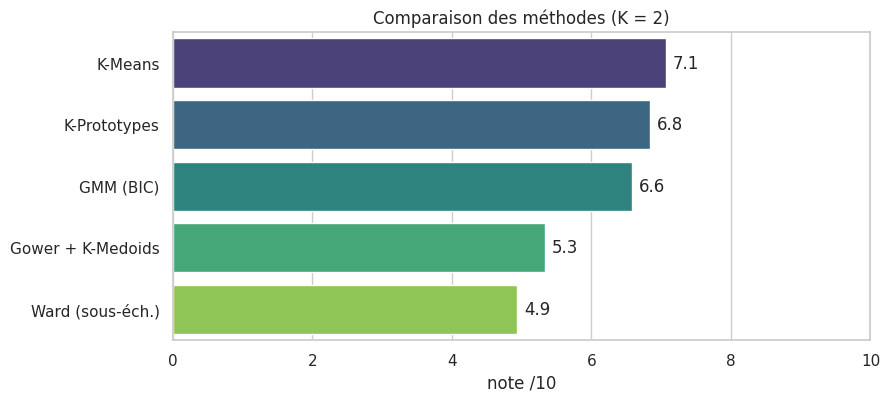

Meilleure méthode sur ces données : K-Means  (7.1/10)


In [34]:
def lin(v, lo, hi): return float(np.clip((v - lo) / (hi - lo), 0, 1) * 10)

WEIGHTS = {"silhouette_PCA": .15, "silhouette_Gower": .15, "davies_bouldin": .10,
           "stabilité_ARI": .20, "équilibre": .10, "V_Cramér_réadm": .20, "temps_s": .10}

notes = pd.DataFrame(index=metrics.index)
notes["silhouette_PCA"]   = metrics["silhouette_PCA"].apply(lin, lo=0, hi=.35)
notes["silhouette_Gower"] = metrics["silhouette_Gower"].apply(lin, lo=0, hi=.30)
notes["davies_bouldin"]   = metrics["davies_bouldin"].apply(lin, lo=3, hi=1)
notes["stabilité_ARI"]    = metrics["stabilité_ARI"].apply(lin, lo=0, hi=1)
notes["équilibre"]        = metrics["équilibre"].apply(lin, lo=0, hi=1)
notes["V_Cramér_réadm"]   = metrics["V_Cramér_réadm"].apply(lin, lo=0, hi=.10)
notes["temps_s"]          = metrics["temps_s"].apply(lambda t: lin(np.log(max(t, 1)), np.log(300), 0))
notes["NOTE /10"] = sum(notes[c] * w for c, w in WEIGHTS.items())
notes = notes.sort_values("NOTE /10", ascending=False)
display(notes.round(1))

fig, ax = plt.subplots(figsize=(9, 4))
sns.barplot(x=notes["NOTE /10"], y=notes.index, ax=ax, palette="viridis")
for i, v in enumerate(notes["NOTE /10"]): ax.text(v + .1, i, f"{v:.1f}", va="center")
ax.set_xlim(0, 10); ax.set_xlabel("note /10"); ax.set_ylabel(""); ax.set_title(f"Comparaison des méthodes (K = {K})"); plt.show()
print(f"Meilleure méthode sur ces données : {notes.index[0]}  ({notes['NOTE /10'].iloc[0]:.1f}/10)")

### 9.5 Visualisation comparée et accord entre méthodes

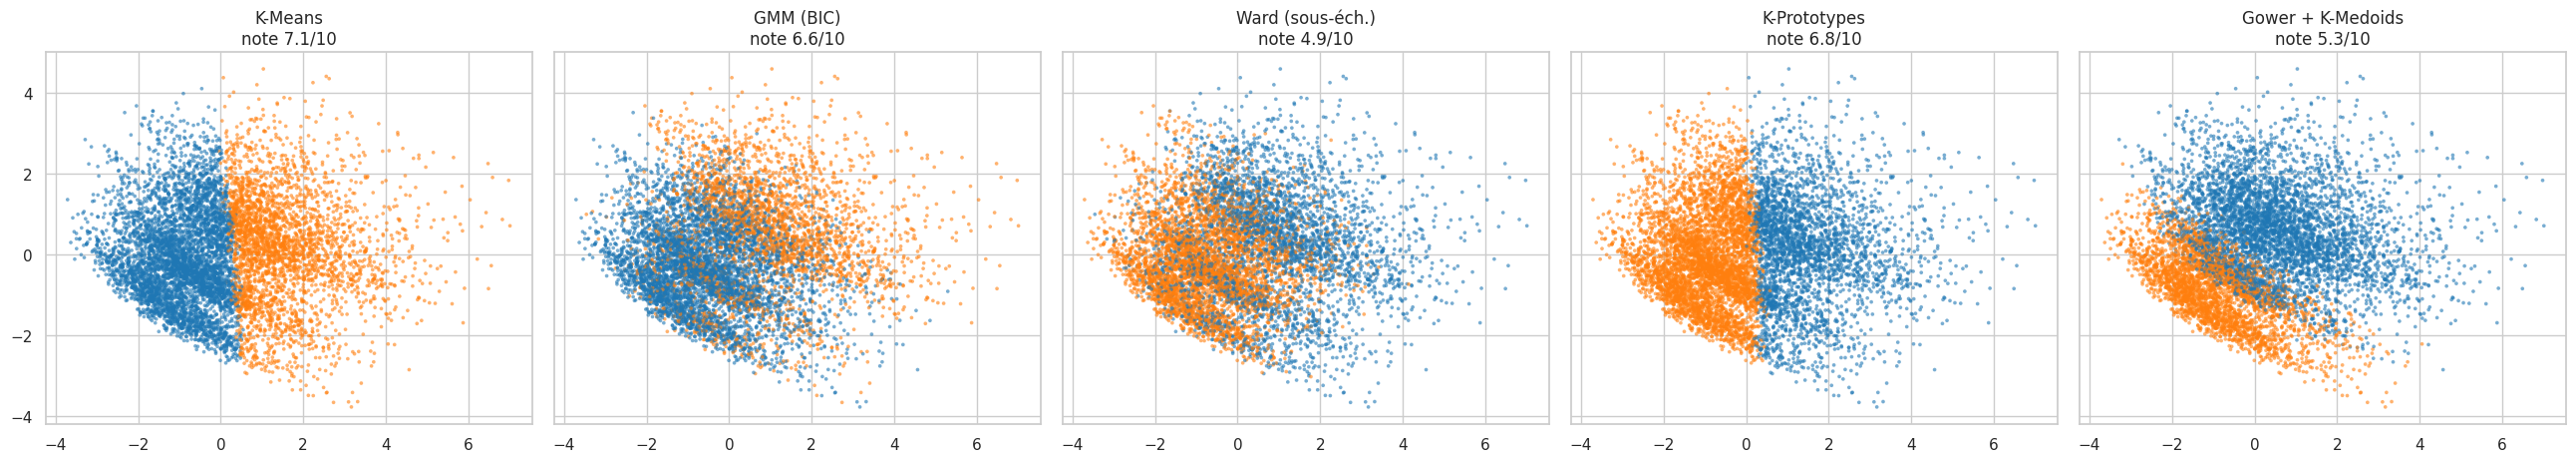

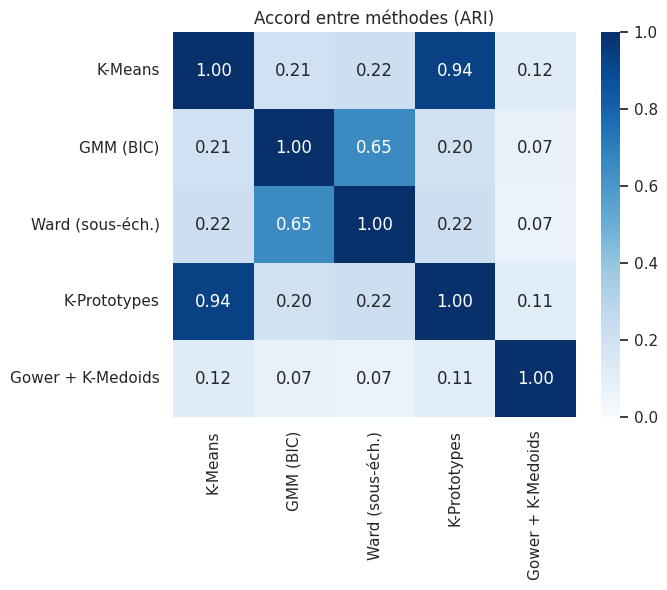

In [35]:
fig, axes = plt.subplots(1, 5, figsize=(26, 4.8), sharex=True, sharey=True)
sub = rng_ext.choice(N, min(8000, N), replace=False)
for ax, name in zip(axes, METHODS):
    sns.scatterplot(x=coords[sub, 0], y=coords[sub, 1], hue=labels_ext[name][sub], palette="tab10", s=7, alpha=.6, linewidth=0, ax=ax, legend=False)
    ax.set_title(f"{name}\nnote {notes.loc[name, 'NOTE /10']:.1f}/10")
plt.tight_layout(); plt.show()

# accord entre méthodes (ARI) : les méthodes trouvent-elles les mêmes groupes ?
names = list(METHODS)
agree = pd.DataFrame([[adjusted_rand_score(labels_ext[a][eval_idx], labels_ext[b][eval_idx]) for b in names] for a in names], index=names, columns=names)
plt.figure(figsize=(6.5, 5)); sns.heatmap(agree, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1)
plt.title("Accord entre méthodes (ARI)"); plt.show()

### 9.6 Lecture des résultats
- La **note finale** résume le compromis qualité géométrique / stabilité / utilité clinique (réadmission) / coût de calcul. Change `WEIGHTS` si tes priorités sont différentes (ex. donne plus de poids à la réadmission si c'est ton objectif).
- **Ward** et **Gower** ne voient qu'un sous-échantillon : leur stabilité et leur temps reflètent ce choix.
- **GMM / BIC** : le BIC sert ici à choisir la covariance ; s'il préfère un `k` plus grand que `K`, ne le suis pas aveuglément (voir 8.3).
- Un **ARI élevé entre deux méthodes** signifie qu'elles retrouvent la même structure : c'est un bon signe de robustesse du découpage.
- *Résultats observés à l'exécution sur les 69 979 patients :* K-Means ≈ 7,1 / K-Prototypes ≈ 6,8 / GMM ≈ 6,6 / Gower + K-Medoids ≈ 5,3 / Ward ≈ 4,9. K-Means arrive en tête et K-Prototypes, qui travaille sur les variables d'origine, donne un résultat très proche : le découpage ne dépend donc pas de l'espace PCA. Ward obtient pourtant le meilleur V de Cramér (≈ 0,13) mais sa stabilité est très mauvaise (ARI ≈ 0,26) : son lien avec la réadmission ne se reproduit pas d'un sous-échantillon à l'autre.

## 10. Validation externe : lien avec la réadmission

La variable `readmitted` n'a **jamais** servi au clustering. Si les groupes obtenus ont des taux de réadmission différents, c'est un signe qu'ils captent une réalité clinique utile.

- **Test du χ²** : les taux de réadmission diffèrent-ils d'un cluster à l'autre ? (p < 0,05 = oui)
- **V de Cramér** : **taille** de l'effet (0 = aucun lien, 1 = lien parfait). Avec ~70 000 patients, le χ² est quasi toujours significatif ; seul le V de Cramér dit si le lien est **important** (repères : < 0,1 faible, 0,1–0,3 modéré, > 0,3 fort).
- **Risque relatif** : taux de réadmission < 30 jours du cluster ÷ taux global.
- **Odds ratio (spécifique à k = 2)** : avec deux groupes seulement, on peut comparer directement le cluster 1 au cluster 0 et donner un **intervalle de confiance à 95 %**.

### 10.1 Taux de réadmission par cluster

readmitted,NO,>30,<30,réadmis (>30 ou <30),risque relatif <30j
cluster,,,,,
0,62.74,29.55,7.71,37.26,0.86
1,53.59,35.35,11.05,46.41,1.23


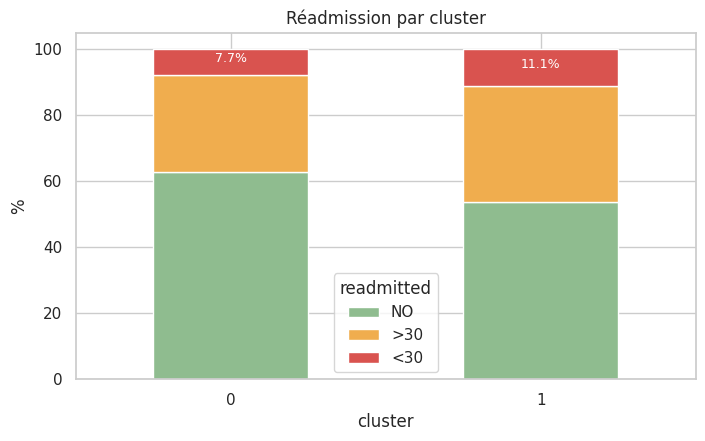

χ² = 613.5 (ddl = 2), p-value = 5.97e-134 → les clusters sont liés à la réadmission
V de Cramér = 0.094  → effet faible


In [36]:
ct = pd.crosstab(clean["cluster"], clean["readmitted"], normalize="index")[["NO", ">30", "<30"]] * 100
ct["réadmis (>30 ou <30)"] = ct[">30"] + ct["<30"]
ct["risque relatif <30j"] = ct["<30"] / (clean["readmitted"] == "<30").mean() / 100
display(ct.round(2))

ax = ct[["NO", ">30", "<30"]].plot(kind="bar", stacked=True, figsize=(8, 4.5), color=["#8fbc8f", "#f0ad4e", "#d9534f"])
for i, (_, r) in enumerate(ct.iterrows()):
    ax.text(i, r["NO"] + r[">30"] + r["<30"] / 2, f"{r['<30']:.1f}%", ha="center", color="white", fontsize=9)
plt.ylabel("%"); plt.title("Réadmission par cluster"); plt.xticks(rotation=0); plt.show()

tab = pd.crosstab(clean["cluster"], clean["readmitted"])
chi2, p, dof, _ = chi2_contingency(tab)
cramer_v = np.sqrt(chi2 / (tab.values.sum() * (min(tab.shape) - 1)))
print(f"χ² = {chi2:.1f} (ddl = {dof}), p-value = {p:.2e} →", "les clusters sont liés à la réadmission" if p < 0.05 else "pas de lien significatif")
print(f"V de Cramér = {cramer_v:.3f}  → effet", "faible" if cramer_v < 0.1 else "modéré" if cramer_v < 0.3 else "fort")

### 10.2 Odds ratio cluster 1 vs cluster 0 (avec intervalle de confiance)
L'**odds ratio** (OR) compare les *cotes* de réadmission : OR = 1 → aucune différence ; OR > 1 → le cluster 1 est plus souvent réadmis. L'IC 95 % est calculé par la méthode de Woolf sur le log de l'OR ; s'il **ne contient pas 1**, la différence est statistiquement significative.

,taux cluster 0 (%),taux cluster 1 (%),odds ratio,IC 95 % bas,IC 95 % haut
critère,,,,,
Réadmission < 30 jours,7.7,11.1,1.49,1.41,1.57
Toute réadmission (>30 ou <30),37.3,46.4,1.46,1.41,1.50


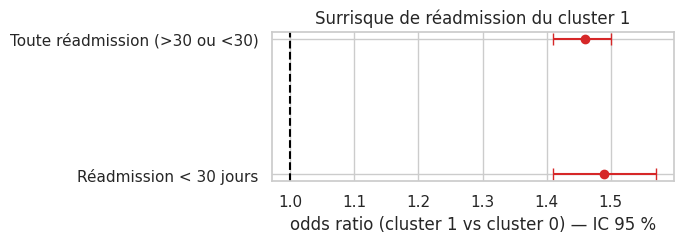

In [37]:
def odds_ratio(exposed, outcome):
    a = int((exposed & outcome).sum());  b = int((exposed & ~outcome).sum())
    c_ = int((~exposed & outcome).sum()); d_ = int((~exposed & ~outcome).sum())
    OR = (a * d_) / (b * c_)
    se = np.sqrt(1/a + 1/b + 1/c_ + 1/d_)
    return OR, np.exp(np.log(OR) - 1.96 * se), np.exp(np.log(OR) + 1.96 * se), a / (a + b), c_ / (c_ + d_)

exposed = (clean["cluster"] == 1).values
outcomes = {"Réadmission < 30 jours": (clean["readmitted"] == "<30").values,
            "Toute réadmission (>30 ou <30)": (clean["readmitted"] != "NO").values}
res = []
for lab_, y in outcomes.items():
    OR, lo, hi, r1, r0 = odds_ratio(exposed, y)
    res.append({"critère": lab_, "taux cluster 0 (%)": round(r0 * 100, 1), "taux cluster 1 (%)": round(r1 * 100, 1),
                "odds ratio": round(OR, 2), "IC 95 % bas": round(lo, 2), "IC 95 % haut": round(hi, 2)})
or_df = pd.DataFrame(res).set_index("critère")
display(or_df)

fig, ax = plt.subplots(figsize=(7, 2.6))
for i, (lab_, r) in enumerate(or_df.iterrows()):
    ax.errorbar(r["odds ratio"], i, xerr=[[r["odds ratio"] - r["IC 95 % bas"]], [r["IC 95 % haut"] - r["odds ratio"]]], fmt="o", color="tab:red", capsize=4)
ax.axvline(1, color="black", ls="--"); ax.set_yticks(range(len(or_df))); ax.set_yticklabels(or_df.index)
ax.set_xlabel("odds ratio (cluster 1 vs cluster 0) — IC 95 %"); ax.set_title("Surrisque de réadmission du cluster 1"); plt.tight_layout(); plt.show()

## 11. Interprétation des 2 clusters

### 11.1 Carte d'identité des clusters

| | **Cluster 0** | **Cluster 1** |
|---|---|---|
| **Nom proposé** | **Séjours courts, prise en charge légère** | **Séjours longs, prise en charge intensive** |
| Taille | 43 373 patients (**62,0 %**) | 26 606 patients (**38,0 %**) |
| Durée de séjour | **3,1 j** | **6,3 j** |
| Médicaments administrés | 12,0 | **21,6** |
| Analyses de laboratoire | 37 | **53** |
| Procédures | 1,1 | **1,9** |
| Diagnostics enregistrés | 6,7 | **8,1** |
| Médicaments antidiabétiques utilisés (moy.) | 0,9 | **1,7** |
| Médicaments dont la dose a été modifiée (moy.) | 0,08 | **0,55** |
| Sous insuline | 36 % | **76 %** |
| Sous metformine | 17 % | **28 %** |
| Traitement modifié pendant le séjour | 25 % | **77 %** |
| Sous traitement antidiabétique (`diabetesMed`) | 65 % | **94 %** |
| Visites externes / urgences / hospitalisations antérieures | 0,23 / 0,07 / 0,12 | **0,37 / 0,15 / 0,27** |
| Âge moyen | 64,3 ans | 67,3 ans |
| Admis via les urgences (source `ER`) | 51,8 % | 55,7 % |
| Sexe (part d'hommes) | 47 % | 47 % |
| Sortie vers un établissement de soins | 14,7 % | **27,3 %** |
| HbA1c > 8 / non testée | 6,6 % / 85,4 % | **12,7 %** / 75,5 % |
| **Réadmission (>30 j ou <30 j)** | **37,3 %** | **46,4 %** |
| **Réadmission < 30 jours** | 7,7 % | **11,1 %** |

*(Valeurs issues des parties 7.2, 7.3, 7.4 et 10, calculées sur les 69 979 patients. Le sexe, le type d'admission et le diagnostic principal sont quasiment identiques dans les 2 groupes. Les deux seules modalités catégorielles sur-représentées (lift ≥ 1,3) sont, dans le cluster 1, la sortie vers un établissement de soins (×1,40) et une HbA1c > 8 (×1,42).)*

### 11.2 Lecture : un seul axe structure les groupes
Avec k = 2, le clustering ne trouve qu'**un seul axe : l'intensité de la prise en charge** (premier axe de l'ACP). Toutes les variables qui s'y rattachent évoluent ensemble : durée de séjour, nombre de médicaments, d'analyses, de procédures, de diagnostics, recours à l'insuline, modifications de traitement. Le cluster 1 est systématiquement au-dessus du cluster 0 sur chacune d'elles : c'est la signature d'un **diabète plus difficile à équilibrer**, qui impose un séjour plus long et un traitement adapté pendant l'hospitalisation.

En revanche, les **antécédents d'urgence** (`number_emergency`) ne jouent presque aucun rôle ici : les deux groupes sont proches (0,07 vs 0,15). Ce n'est pas que cette dimension n'existe pas : un petit sous-groupe de patients très fréquents aux urgences est simplement **noyé** dans les deux grands groupes (voir 7.6, où k = 3 le fait apparaître).

### 11.3 Description de chaque groupe
- **Cluster 0 — « Séjours courts, prise en charge légère » (62,0 %).** Le groupe majoritaire : patients peu complexes, hospitalisés environ 3 jours, avec une douzaine de médicaments, très peu de changements de traitement (0,08 en moyenne) et rarement sous insuline (36 %). Ils retournent majoritairement à domicile. Le **taux de réadmission est le plus bas** (37,3 %, dont 7,7 % sous 30 jours).
- **Cluster 1 — « Séjours longs, prise en charge intensive » (38,0 %).** Séjours deux fois plus longs, près de 22 médicaments, 53 analyses de laboratoire, insuline chez 3 patients sur 4 et traitement modifié dans 77 % des cas. Ces patients sont un peu plus âgés et envoyés plus souvent vers un établissement de soins à la sortie. Le **taux de réadmission est plus élevé** (46,4 %, dont 11,1 % sous 30 jours).

### 11.4 Lien avec la réadmission (validation externe)
Les deux groupes sont **ordonnés** du point de vue du risque : la réadmission passe de **37,3 % à 46,4 %**, soit **+9 points**, et la réadmission sous 30 jours de 7,7 % à 11,1 % (risque relatif d'environ 0,86 pour le cluster 0 contre 1,23 pour le cluster 1 par rapport à la moyenne). Le test du χ² (χ² ≈ 613, p ≈ 6·10⁻¹³⁴) confirme que la différence est **statistiquement certaine**, mais son **ampleur reste faible** : V de Cramér ≈ 0,094. Les clusters aident à **repérer** des profils à risque, ils ne **prédisent** pas la réadmission d'un patient donné. La cellule 10.2 chiffre le surrisque par un odds ratio avec intervalle de confiance.

Cette hiérarchie est **cliniquement cohérente** : une maladie plus lourde et plus difficile à contrôler est un facteur connu de réadmission.

### 11.5 Utilité pratique
| Groupe | Piste d'action |
|---|---|
| Cluster 0 | Parcours standard, sortie rapide, suivi de routine |
| Cluster 1 | Optimisation du contrôle glycémique (HbA1c), planification de la sortie (établissements de soins), éducation thérapeutique, suivi renforcé après la sortie |

### 11.6 Ce que k = 2 ne montre pas
Un découpage en deux groupes est **facile à communiquer**, mais il est grossier : il ne distingue pas le sous-groupe des **patients récurrents des urgences** (petit groupe qui apparaît à k = 3 avec le taux de réadmission le plus élevé du jeu de données). La table croisée de 7.6 le montre : ces patients (7,2 % à k = 3) sont répartis presque **moitié-moitié** entre les clusters 0 (48 %) et 1 (52 %) de k = 2, alors que les deux autres groupes de k = 3 se retrouvent à 99 % dans un seul cluster de k = 2. Le passage de k = 2 à k = 3 consiste donc à **extraire** ce petit groupe, sans remettre en cause la séparation « léger / intensif ». Si l'objectif est de **cibler un suivi renforcé**, k = 3 est plus informatif ; si l'objectif est une **segmentation simple** (court/léger vs long/intensif), k = 2 suffit.

## 12. Évaluation globale

### 12.1 Évaluation de la comparaison des algorithmes (k = 2)
Le tableau détaillé est **calculé en 8.6 et 8.9** (silhouette, Davies-Bouldin, Calinski-Harabasz, taille du plus petit cluster, bruit, ARI, NMI). Les points à retenir pour la lecture :

1. **Les silhouettes des solutions « équilibrées » restent faibles** (KMeans 0,13 ; GMM 0,13–0,17) : les patients forment plutôt un **continuum** que des groupes naturellement séparés ; k = 2 est un découpage utile d'un continuum, pas une frontière naturelle.
2. **Les meilleurs scores bruts sont trompeurs.** Hiérarchique *ward* / *complete* (silhouette ≈ 0,22–0,23, plus petit cluster ≈ 7 %) et DBSCAN (≈ 0,19, un cluster de ≈ 5 %) obtiennent de meilleures silhouettes que KMeans, mais parce qu'ils **isolent une petite minorité atypique** et laissent tout le reste dans un seul bloc (ARI vs KMeans ≈ 0,02) : ils ne coupent pas le continuum en deux groupes cliniques. Hiérarchique *average* (silhouette 0,46) isole même 0,3 % des patients : solution inexploitable. Regarde toujours `plus petit cluster (%)` et `ARI vs KMeans`.
3. **DBSCAN** ne trouve pas de zones denses séparées : à k = 2 il retient un grand bloc, un petit groupe et un peu de bruit, ce qui confirme l'absence de frontières nettes.
4. Dans la comparaison /10 de la partie 9, **K-Means** est en tête (≈ 7,1), suivi de très près par **K-Prototypes** (≈ 6,8) qui travaille sur les variables d'origine ; Ward et Gower, ajustés sur un sous-échantillon, sont pénalisés en **stabilité** (ARI ≈ 0,26 et 0,62 contre 0,98 pour KMeans).

→ **KMeans k = 2** est le choix le plus raisonnable : seul à donner deux groupes **équilibrés (62 % / 38 %)**, très stable (ARI ≈ 0,99), scalable sur l'ensemble des patients et facile à interpréter.

### 12.2 Tableau de bord du clustering final (KMeans k = 2, tous les patients)

In [38]:
# Tableau de bord de l'évaluation du clustering final (KMeans k=2 sur l'ensemble des patients)
sil_full = silhouette_score(X_pca, labels_full, sample_size=15000, random_state=RANDOM_STATE)
dbi_full = davies_bouldin_score(X_pca, labels_full)
chi_full = calinski_harabasz_score(X_pca, labels_full)
nmi_full = normalized_mutual_info_score(clean["readmitted"], labels_full)

bilan = pd.DataFrame({
    "valeur": [round(sil_full, 3), round(dbi_full, 3), round(chi_full, 0),
               f"{pct_seeds:.0f} % des runs (ARI moyen {np.mean(ari_seeds):.2f})",
               f"{pct_boot:.0f} % des runs (ARI moyen {np.mean(ari_boot):.2f})",
               round(float(sizes['part_%'].min()), 1), round(cramer_v, 3), round(nmi_full, 4),
               f"{fid*100:.1f} %"],
    "repère": ["0,1–0,3 = structure faible à modérée ; > 0,5 = forte", "plus bas = mieux (< 1 = très bon)",
               "plus haut = mieux (comparable seulement à k égal)", "100 % = totalement reproductible",
               "100 % = totalement reproductible", "pas de cluster minuscule (> 5 %)",
               "< 0,1 faible ; 0,1–0,3 modéré ; > 0,3 fort", "≈ 0 = peu d'information partagée",
               "proche de 100 % = clusters décrits par des règles simples"]},
    index=["Silhouette", "Davies-Bouldin", "Calinski-Harabasz", "Reproductibilité (graines)",
           "Reproductibilité (sous-échantillons)", "Plus petit cluster (%)", "V de Cramér vs readmitted", "NMI vs readmitted",
           "Fidélité de l'arbre de substitution"])
display(bilan)

,valeur,repère
Silhouette,0.13,"0,1–0,3 = structure faible à modérée ; > 0,5 =..."
Davies-Bouldin,2.705,plus bas = mieux (< 1 = très bon)
Calinski-Harabasz,8636.0,plus haut = mieux (comparable seulement à k égal)
Reproductibilité (graines),100 % des runs (ARI moyen 0.99),100 % = totalement reproductible
Reproductibilité (sous-échantillons),100 % des runs (ARI moyen 0.99),100 % = totalement reproductible
Plus petit cluster (%),38.0,pas de cluster minuscule (> 5 %)
V de Cramér vs readmitted,0.094,"< 0,1 faible ; 0,1–0,3 modéré ; > 0,3 fort"
NMI vs readmitted,0.0056,≈ 0 = peu d'information partagée
Fidélité de l'arbre de substitution,86.4 %,proche de 100 % = clusters décrits par des règ...


### 12.3 Verdict : forces et faiblesses

| Critère | Résultat | Verdict |
|---|---|---|
| **Séparation interne** (silhouette ≈ 0,13 ; Davies-Bouldin ≈ 2,7 ; ≈ 15 % de patients à silhouette négative) | Les 2 clusters se **chevauchent** : structure faible. Davies-Bouldin est moins bon qu'à k = 3 (≈ 2,3) ; la silhouette est quasi identique (0,130 vs 0,133) | ⚠️ Faible |
| **Équilibre des tailles** (62,0 % / 38,0 %) | Aucun cluster minuscule | ✅ Bon |
| **Stabilité** | **100 %** des lancements (graines et sous-échantillons à 80 %) retrouvent la même partition, ARI moyen ≈ 0,99 : pas de second minimum local, contrairement à k = 3 | ✅ Excellente |
| **Interprétabilité** | 2 profils nets, un seul axe (intensité de prise en charge) ; un arbre de profondeur 3 (nombre de médicaments, modification du traitement, durée de séjour) retrouve le cluster de **86 %** des patients | ✅ Très bonne |
| **Cohérence clinique** | Gradient de réadmission **37,3 % → 46,4 %** conforme à l'attendu | ✅ Bonne |
| **Pouvoir prédictif de la réadmission** | χ² très significatif mais V de Cramér ≈ 0,094 | ⚠️ Faible (normal : clustering non supervisé) |
| **Finesse du découpage** | Le sous-groupe des patients récurrents des urgences (7,2 %, 1,43 passage aux urgences en moyenne) n'est pas isolé ; ARI k=2 / k=3 = 0,83. En revanche le V de Cramér est légèrement meilleur à k = 2 (0,094 vs 0,085) | ⚠️ Perte d'information par rapport à k = 3 |
| **Comparaison d'algorithmes** | Les silhouettes plus élevées (Ward, complete, DBSCAN) viennent de clusters minoritaires de 5–8 % ; KMeans est 1er sur la note /10, K-Prototypes (variables d'origine) arrive aux mêmes conclusions | ✅ Choix de KMeans justifié |

### 12.4 Limites de l'étude
- **Structure faible** : avec une silhouette ≈ 0,13, les 2 groupes sont un **découpage utile d'un continuum**, pas des catégories naturelles de patients. Les patients proches de la frontière peuvent passer d'un groupe à l'autre.
- **k = 2 est grossier** : il résume l'essentiel (intensité de la prise en charge) mais écrase des profils plus fins (voir 7.6).
- **Variables mixtes** : le mélange numériques standardisées / one-hot / binaires avec une distance euclidienne n'est pas idéal ; la PCA (90 % de variance) réduit mais ne règle pas ce problème. K-Prototypes et Gower (partie 9) sont là pour vérifier la robustesse.
- **Un seul séjour par patient** (le premier) : perte d'information sur le parcours dans le temps.
- **Valeurs manquantes importantes** : HbA1c et glycémie non réalisées chez 75–95 % des patients ; `diag_2`, `diag_3`, `race`, `medical_specialty` écartées.
- **Comparaison sur un échantillon** (10 000 patients) pour les algorithmes en O(n²) ; les résultats chiffrés de la partie 8 peuvent légèrement différer sur l'ensemble des données (par exemple, la silhouette de KMeans est de 0,131 sur l'échantillon et 0,130 sur les 69 979 patients).
- **Données anciennes** (1999–2008, hôpitaux américains) : les pratiques actuelles ont évolué.
- **Association ≠ causalité** : un taux de réadmission plus élevé dans un groupe ne signifie pas que le groupe *cause* la réadmission. L'intensité du séjour est plutôt le **reflet de la gravité** de la maladie.

### 12.5 Pistes d'amélioration
- Comparer avec **k = 3** (déjà esquissé en 7.6) pour isoler les patients récurrents des urgences ;
- Essayer une réduction non linéaire (**UMAP**) avant le clustering ;
- Ajouter des variables écartées (`diag_2/3`, spécialité médicale) via un regroupement ICD-9 ;
- Évaluer k de façon plus robuste (**gap statistic**, consensus clustering) ;
- Pour **prédire** la réadmission, utiliser un modèle supervisé (régression logistique, gradient boosting) et considérer le cluster comme variable explicative supplémentaire.

### 12.6 Conclusion générale
Le clustering **KMeans à k = 2** sur 69 979 patients diabétiques (un séjour par patient) identifie deux profils **cliniquement lisibles**, séparés par un seul axe : **(0)** des séjours courts à prise en charge légère (62,0 %), taux de réadmission 37,3 % ; **(1)** des séjours longs et intensifs, à diabète plus difficile à équilibrer (38,0 %), taux de réadmission 46,4 % (11,1 % sous 30 jours).

La **comparaison des algorithmes** montre qu'aucune méthode ne révèle de groupes nettement séparés : les patients forment un **continuum**, et KMeans, très stable (ARI ≈ 0,99) et aussi performant que les alternatives équilibrées (y compris K-Prototypes sur les variables d'origine), est le choix le plus simple, le plus rapide et le plus interprétable. Les clusters sont **utiles pour décrire et prioriser** mais **trop peu prédictifs** (V de Cramér ≈ 0,09) pour remplacer un modèle supervisé. Enfin, k = 2 est un découpage **volontairement simple** : il perd le sous-groupe des patients récurrents des urgences, qu'un découpage à k = 3 met en évidence.

## 13. Sauvegarde des résultats
Le fichier `diabetes_clusters.csv` contient les variables nettoyées, la cible `readmitted`, le cluster KMeans final et les clusters des autres méthodes de la partie 9. `notes_methodes.csv` contient les notes /10, `comparaison_algorithmes.csv` le tableau de la partie 8.

In [39]:
clean["cluster_kmeans"] = clean["cluster"]
for name, lab in labels_ext.items():
    clean["cluster_" + name.split()[0].lower().replace("-", "")] = lab
clean.to_csv("diabetes_clusters.csv", index=False)
notes.round(2).to_csv("notes_methodes.csv")
comp_sorted.to_csv("comparaison_algorithmes.csv")
print("Fichiers sauvegardés : diabetes_clusters.csv", clean.shape, "| notes_methodes.csv | comparaison_algorithmes.csv")

Fichiers sauvegardés : diabetes_clusters.csv (69979, 29) | notes_methodes.csv | comparaison_algorithmes.csv


## 14. Export du Bundle pour Déploiement Web (DiaCareApp)

Cette cellule sauvegarde l'ensemble des objets scikit-learn entraînés (`StandardScaler`, `PCA`, `KMeans`, `PCA 2D`) ainsi que les métadonnées et profils de clusters nécessaires pour permettre le déploiement temps réel dans une application web comme **DiaCareApp**.

In [40]:
import os, json, joblib

# 1. Calcul du transformateur PCA 2D pour les visualisations interactives dans l'application web
pca_2d = PCA(n_components=2, random_state=RANDOM_STATE).fit(X)

# 2. Récupération des profils moyens et lifts pour l'interprétation clinique
cluster_profiles = {}
for c in effect.index:
    top_num = effect.loc[c].reindex(effect.loc[c].abs().sort_values(ascending=False).index).head(5)
    top_features = {
        feat: {
            "z_score": round(float(val), 2),
            "cluster_mean": round(float(prof.loc[c, feat]), 2),
            "global_mean": round(float(clean[feat].mean()), 2)
        }
        for feat, val in top_num.items()
    }

    overrepresented_cats = []
    for cf in cat_feats:
        share_c = clean.loc[clean["cluster"] == c, cf].value_counts(normalize=True)
        share_g = clean[cf].value_counts(normalize=True)
        for m, s in share_c.items():
            lift = s / share_g[m]
            if lift >= 1.3 and s >= 0.05:
                overrepresented_cats.append({
                    "feature": cf,
                    "modality": str(m),
                    "share_cluster_pct": round(float(s * 100), 1),
                    "share_global_pct": round(float(share_g[m] * 100), 1),
                    "lift": round(float(lift), 2)
                })

    cluster_profiles[int(c)] = {
        "size": int(sizes.loc[c, "effectif"]),
        "pct": float(sizes.loc[c, "part_%"]),
        "readmission_pct": round(float((clean.loc[clean["cluster"] == c, "readmitted"] != "NO").mean() * 100), 1),
        "readmission_lt30_pct": round(float((clean.loc[clean["cluster"] == c, "readmitted"] == "<30").mean() * 100), 1),
        "top_features": top_features,
        "overrepresented_cats": overrepresented_cats
    }

# 3. Fit d'un StandardScaler sur X_num propre pour l'inférence
X_num_raw = clean[num_feats].copy()
X_num_raw[skewed] = np.log1p(X_num_raw[skewed])
scaler_deploy = StandardScaler().fit(X_num_raw)

# 4. Création du bundle exportable
cluster_bundle = {
    "num_feats": num_feats,
    "bin_feats": bin_feats,
    "cat_feats": cat_feats,
    "skewed": skewed,
    "columns_after_dummies": list(X.columns),
    "scaler": scaler_deploy,
    "pca": pca,
    "pca_2d": pca_2d,
    "km": km,
    "remap": remap,
    "k": K
}

# Sauvegarde locale (dossier séparé de celui du k = 3 pour ne pas l'écraser)
os.makedirs("model_k2", exist_ok=True)
joblib.dump(cluster_bundle, "model_k2/cluster_bundle.joblib")
with open("model_k2/cluster_profiles.json", "w", encoding="utf-8") as f:
    json.dump(cluster_profiles, f, indent=2, ensure_ascii=False)

# Sauvegarde également dans DiaCareApp si le dossier existe
diacare_model_dir = os.path.join("DiaCareApp", "DiaCareApp", "model_k2")
if os.path.exists(os.path.dirname(diacare_model_dir)):
    os.makedirs(diacare_model_dir, exist_ok=True)
    joblib.dump(cluster_bundle, os.path.join(diacare_model_dir, "cluster_bundle.joblib"))
    with open(os.path.join(diacare_model_dir, "cluster_profiles.json"), "w", encoding="utf-8") as f:
        json.dump(cluster_profiles, f, indent=2, ensure_ascii=False)
    print("Bundle sauvegardé dans :", diacare_model_dir)

print("Export clustering terminé avec succès : model_k2/cluster_bundle.joblib et model_k2/cluster_profiles.json")

Export clustering terminé avec succès : model_k2/cluster_bundle.joblib et model_k2/cluster_profiles.json
